# Sprint 14 — Projeto Final: Olist, recompra de clientes

### por Luiz Trajano

---

## Contexto

A Olist liga pequenos lojistas aos grandes marketplaces do Brasil. Na base pública de 2016 a 2018, quase todo cliente compra uma vez só e não volta. Isso custa caro: cada venda nova depende de atrair um cliente novo, enquanto quem já comprou poderia voltar sem esse custo.

Neste projeto coloco em prática a decomposição aprovada. Quero descobrir o que acontece na primeira compra (entrega, nota, frete e região) que separa quem volta de quem não volta, e onde a Olist e os lojistas podem agir para que mais clientes voltem.

Acompanho cada pessoa a partir da primeira compra, numa coorte em que todos tiveram o mesmo tempo para voltar, e testo cinco hipóteses: o atraso na entrega (H1), a nota baixa (H2), o peso do frete (H3), o estado do cliente (H4) e se o atraso afasta o cliente por derrubar a nota (H5). As regras e os KPIs estão na seção 1.

Entrego também neste notebook, um dashboard com os KPIs e filtros e uma apresentação no formato CAR para quem decide, com os links na célula abaixo.

## Entregáveis

- **Pasta da entrega (Google Drive):** [Sprint 14 - Projeto Final - Luiz Trajano](https://drive.google.com/drive/folders/10n7bOXmhWHwr5AslICo6ESCLsodLdQNm)
- **Dashboard (Tableau Public):** [Recompra Olist - Projeto Final](https://public.tableau.com/views/RecompraOlist-ProjetoFinal/Painel1?:language=pt-BR&:showVizHome=no&:display_count=n&:origin=viz_share_link)
- **Apresentação final no formato CAR (PDF):** [Recompra na Olist.pdf](https://drive.google.com/file/d/10Jh0CFgbyE04AElG05ohpardC4gFAGJa/view)

## Índice

- [0. Setup](#0.-Setup)
- [1. O plano aprovado](#1.-O-plano-aprovado)
- [2. Os dados e a preparação](#2.-Os-dados-e-a-preparação)
- [3. Análise exploratória](#3.-Análise-exploratória)
- [4. Validação das hipóteses](#4.-Validação-das-hipóteses)
- [5. KPIs consolidados e base do dashboard](#5.-KPIs-consolidados-e-base-do-dashboard)
- [6. Conclusão geral e recomendações](#6.-Conclusão-geral-e-recomendações)

---

# 0. Setup

Carrego as bibliotecas que uso no projeto inteiro: pandas e numpy para preparar os dados, matplotlib e seaborn para os gráficos e scipy para os testes. Aplico o meu estilo de gráficos das outras sprints e fixo as cores do projeto, que são as mesmas no dashboard e na apresentação: quem voltou em azul, quem não voltou em vermelho e as referências em cinza. As constantes da análise (janela, datas, ALFA, limites) não ficam aqui. Elas ficam na célula onde são usadas, para que a regra apareça junto com a conta.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from scipy import stats

pd.set_option('display.max_columns', None)

# --- Meu estilo visual (padrão das outras Sprints) ---
meu_estilo = {
    'figure.figsize':   (12, 5),
    'figure.facecolor': '#0d0d0d',
    'axes.facecolor':   '#0d0d0d',
    'savefig.facecolor':'#0d0d0d',
    'axes.edgecolor':   '#333333',
    'axes.labelcolor':  '#aaaaaa',
    'axes.titlecolor':  '#ffffff',
    'text.color':       '#aaaaaa',
    'xtick.color':      '#aaaaaa',
    'ytick.color':      '#aaaaaa',
    'grid.color':       '#222222',
    'axes.grid':        True,
    'axes.grid.axis':   'y',
    'axes.axisbelow':   True,
    'axes.prop_cycle':  cycler(color=['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']),
    'savefig.dpi':      150,
    'savefig.bbox':     'tight',
    'legend.facecolor': '#1a1a1a',
    'legend.edgecolor': '#333333',
}
sns.set_theme(style='dark', rc=meu_estilo)   # seaborn primeiro, meu rc por cima
plt.rcParams.update(meu_estilo)
CORES = ['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']

# cores fixas do projeto (decomposição 5.2), as mesmas no dashboard e na apresentação
COR_VOLTOU = '#5B6BF5'
COR_NAO_VOLTOU = '#FF6B6B'
COR_REFERENCIA = '#888888'

PASTA_IMAGENS = 'images'
os.makedirs(PASTA_IMAGENS, exist_ok=True)

---

# 1. O plano aprovado

## 1.1 Problema, perguntas, hipóteses e KPIs

Resumo aqui o que a decomposição aprovada definiu, para que este notebook possa ser lido sozinho. O detalhe de cada decisão está na decomposição.

**Pergunta principal.** O que acontece na primeira compra (entrega, nota, frete e região) que separa o cliente que volta a comprar do que compra uma vez só, e onde a Olist e os lojistas podem agir para que mais clientes voltem?

**Perguntas derivadas.**

a. O atraso na primeira entrega diminui a chance de o cliente voltar?

b. Uma nota baixa na primeira compra diminui a chance de o cliente voltar?

c. Quando o frete pesa muito no valor do pedido, o cliente volta menos?

d. A chance de o cliente voltar muda conforme o estado em que ele mora?

e. O atraso derruba a nota, e é por causa dessa nota que o cliente não volta?

**Definições que valem para o notebook inteiro.**

- Cliente é a pessoa (`customer_unique_id`), não o cadastro do pedido (`customer_id`), que muda a cada pedido.
- Recompra é um novo pedido da mesma pessoa, feito em outro dia e até 180 dias depois da primeira compra. Pedido no mesmo dia não conta, porque costuma ser a mesma compra dividida em vários pedidos.
- Só entra na conta quem teve a janela inteira dentro do período útil (a coorte). Quem comprou pela primeira vez perto do fim da base não teve tempo de voltar.
- Tudo o que uso para explicar a volta vem da primeira compra. Usar dado de um pedido posterior seria explicar a volta com algo que aconteceu depois dela.

**Hipóteses, na ordem de prioridade do revisor.**

| # | Hipótese | Como testo | Seção |
|---|---|---|---|
| H1 (a) | Quem recebe a primeira compra atrasada volta menos. | Teste z de proporções, atrasou ou não | 4.2 |
| H2 (b) | Quem dá nota baixa na primeira compra volta menos, e menos ainda com nota 1. | Qui-quadrado nos três grupos de nota; se rejeitar H0, z de cada grupo baixo contra a nota alta, com Holm | 4.3 |
| H5 (e) | O atraso reduz a recompra porque derruba a nota. | z da proporção de nota de 1 a 3 com e sem atraso; z do atraso dentro de cada grupo de nota, com Holm | 4.4 |
| H3 (c) | Quem paga um frete pesado em relação ao produto volta menos. | Mann-Whitney, porque o peso do frete é assimétrico | 4.5 |
| H4 (d) | A recompra muda conforme o estado do cliente. | Qui-quadrado; se rejeitar H0, z entre os grupos, com Holm | 4.6 |

**Regras dos testes.** O nível de significância é 5%, guardado em `ALFA` antes de qualquer teste (seção 4.1). A correção de Holm vale dentro de cada hipótese que tem mais de uma comparação. Os dados são observacionais, então um resultado significativo mostra associação e não prova que a ação traz o cliente de volta. Não rejeitar H0 também não prova que não há efeito, porque o grupo que volta é pequeno. Por isso olho o tamanho da diferença junto com o p-valor.

**KPIs.**

Nas fórmulas de grupo, `g` é o grupo analisado (por exemplo, quem teve atraso) e `r` é o grupo de referência com que ele é comparado (por exemplo, quem não teve atraso). A fórmula é a mesma em todas as hipóteses; só mudam os dois grupos.

```
recompra = pessoas da coorte com outro pedido, em outro dia, dentro da janela
          / pessoas da coorte

recompra_g = pessoas do grupo g que voltaram / pessoas do grupo g

diferenca_absoluta = recompra_g - recompra_r                  (em pontos percentuais)
diferenca_relativa = (recompra_g - recompra_r) / recompra_r   (em %)

taxa_atraso = primeiras compras entregues depois da data estimada
              / primeiras compras entregues com data

nota_baixa = primeiras compras com nota de 1 a 3 / primeiras compras com avaliação

peso_frete = soma de freight_value dos itens do pedido
             / soma de price dos itens do pedido
```

A referência da recompra é a taxa da própria coorte. Um grupo é "ruim" quando fica abaixo dela com diferença significativa no teste. Mostro a diferença absoluta e a relativa juntas porque, com uma recompra tão baixa, uma diferença relativa grande pode representar poucos clientes.

## 1.2 O que mudou depois da revisão

O revisor aprovou a decomposição e deixou sete pontos para esta implementação. Registro aqui o que faço com cada um e onde ele aparece.

1. **Fim do período útil.** Na decomposição, `FIM_PERIODO_UTIL = '2018-08'` virava 01/08/2018 na conversão para data, e a coorte perdia um mês. Sigo a correção do revisor: `FIM_PERIODO_UTIL = '2018-08-31'`. Como essa data vira 01/09 após a meia-noite, comparo as datas sem a hora (`.dt.normalize()`) com `<=`, para que um pedido feito em 31/08 às 14h também entre (seção 2.3).

2. **Pessoas sem pedido entregue no primeiro dia.** O revisor contou 2.805 pessoas nesse caso, e eu recalculo o número na seção 2.3. Mantenho todas na coorte: elas compraram, e um pedido cancelado ou indisponível pode ser justamente o motivo de não voltar. Elas ficam fora só das contas de atraso, porque não têm data de entrega, e ganham uma coluna que vai marcar cada uma para eu mostrar a recompra delas à parte (seções 2.3 e 3.1).

3. **Várias compras no primeiro dia.** Os pedidos do mesmo dia contam como uma compra só. Se algum deles atrasou, a primeira compra atrasou. Se tiveram notas diferentes, fico com a pior (seções 2.3 e 2.4). Na seção 4.7 confiro se o resultado muda sem essas pessoas.

4. **Janela de 180 dias.** Mantida. Na seção 4.7 comparo 90, 180 e 365 dias numa tabela para ver se a direção dos resultados se mantém.

5. **Prioridade.** H1, H2 e H5 vêm primeiro e H3 e H4 completam a análise. A regressão logística na H5 fica como opcional.

6. **Leitura dos dados.** Mantenho o try/except da decomposição: leio a cópia local em `data/` e, se ela não existir, o link do Kaggle (seção 2.1).

7. **Tabelas dentro de laço.** Uso `display()` em vez de `print()`, para a tabela sair formatada.

---

# 2. Os dados e a preparação

## 2.1 Leitura e visão geral

Leio os 4 arquivos que a decomposição escolheu: `orders`, `items`, `reviews` e `customers`. Como a leitura é igual para os quatro, faço uma função com docstring e chamo num laço. A função tenta a cópia local em `data/` e, se não achar, lê pelo link do Kaggle, que o revisor aceitou para a plataforma. Mostro linhas, colunas e uma amostra de cada tabela com `display()`, para conferir se batem com a decomposição antes de mexer em qualquer coisa. Faço isso pois ganho tempo e espaço neste notebook, otimizando estas tarefas.

In [2]:
RANDOM_STATE = 42    # mesma amostra a cada execução


def ler_olist(arquivo):
    """Lê um CSV da base Olist: a cópia local em data/ ou, se ela não existir, o link do Kaggle.

    Parâmetros
    ----------
    arquivo : nome do CSV (ex.: 'olist_orders_dataset.csv').

    Retorna
    -------
    DataFrame : a tabela lida, sem nenhum tratamento.
    """
    try:
        return pd.read_csv(f'data/{arquivo}')
    except FileNotFoundError:
        # na plataforma não há cópia local: o Kaggle entrega o arquivo em zip, e o compression extrai na leitura
        return pd.read_csv(
            f'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce/{arquivo}',
            compression='zip',
        )


# os 4 arquivos da decomposição: um nome curto para cada um
arquivos = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
}

# laço: a mesma leitura para os 4 arquivos, guardada num dicionário pelo nome curto
tabelas = {}
for nome, arquivo in arquivos.items():
    tabelas[nome] = ler_olist(arquivo)

orders = tabelas['orders']
items = tabelas['items']
reviews = tabelas['reviews']
customers = tabelas['customers']

# shape[0] = linhas e shape[1] = colunas de cada tabela, numa tabela só
visao_geral = pd.DataFrame(
    {'linhas': [tabela.shape[0] for tabela in tabelas.values()],
    'colunas': [tabela.shape[1] for tabela in tabelas.values()]},
    index=tabelas.keys(),
)
display(visao_geral)

# sample com random_state: linhas sorteadas de toda a tabela, e não só as primeiras, sempre as mesmas
# display() dentro do laço para a amostra sair como tabela formatada (ponto 7 da seção 1.2)
for nome, tabela in tabelas.items():
    print(f'--- {nome}')
    display(tabela.sample(5, random_state=RANDOM_STATE))

,linhas,colunas
orders,99441,8
items,112650,7
reviews,99224,7
customers,99441,5


--- orders


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
52263,b9a6c5f5df52c7226ac85aee7524c27f,f160aaf480efdfa7268f0fa535f73e76,delivered,2018-06-12 20:07:44,2018-06-12 20:44:26,2018-06-13 13:09:00,2018-06-19 12:44:08,2018-07-17 00:00:00
46645,261e71d2349c713eafa9f3df5972b95d,d6708bbbd2d419475869a84e41f620a1,delivered,2018-01-20 12:15:57,2018-01-20 12:37:13,2018-01-25 21:42:52,2018-01-30 11:32:35,2018-02-15 00:00:00
37546,67b50899f52995848c427e361e10dde3,1b353c00c71689afba44554e43cc5a76,delivered,2018-06-16 21:24:10,2018-06-16 21:36:59,2018-06-21 13:55:00,2018-06-27 13:17:27,2018-07-16 00:00:00
94756,32733fc014b67ef70fa6039dd8c6ba82,ad66699beab381d0747605f108cc02b4,delivered,2017-08-30 21:12:28,2017-08-31 02:50:24,2017-09-12 20:16:46,2017-09-25 17:53:23,2017-09-22 00:00:00
14771,39a70e9e9b729b11dee34ac12478597f,20c678bfce3c8252288f70dd2bee5e51,delivered,2017-08-10 21:26:25,2017-08-10 21:44:13,2017-08-11 19:11:16,2017-08-22 16:45:00,2017-09-12 00:00:00


--- items


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
107777,f4ee4273538924bda6212f5948e80fde,1,69455f41626a745aea9ee9164cb9eafd,7d13fca15225358621be4086e1eb0964,2018-06-19 09:18:15,180.00,20.45
2391,056349f85a73d794119c4286c95a52de,1,af35be35db4ad0dc288b571453337376,d20b021d3efdf267a402c402a48ea64b,2017-03-09 14:35:09,10.99,16.05
77829,b124967afcc82ef17ec41020fe2a9136,1,12e6d0f655986ceff00c74658dec97b1,3be634553519fb6536a03e1358e9fdc7,2018-06-06 17:18:09,49.99,8.88
99819,e257ae8610fb4fb68a1f459c3a4b1f51,1,a50acd33ba7a8da8e9db65094fa990a4,8581055ce74af1daba164fdbd55a40de,2017-05-18 08:02:19,117.30,14.43
41297,5e114d8e3840661abc3d9c4820f427b3,1,5cca3efb9521cc1d7099d610d4a12017,3d871de0142ce09b7081e2b9d1733cb1,2018-05-03 18:15:09,58.90,13.77


--- reviews


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
90252,406e32984dd5273582105460a79571af,e00ed9d20c3479f9f0e9727ca9d60946,5,NaN,NaN,2017-12-22 00:00:00,2017-12-22 21:10:19
24436,3bca8d9922bed47eb96f23d121945290,3b5351f5f99b46339212291661a9d226,5,NaN,Cumpriu o acordado!,2018-04-10 00:00:00,2018-04-13 01:57:05
11313,65895b807ac5dfe062c82400b3f210b8,f395e98fb5c1c6ce1306e80de2fe125b,4,NaN,NaN,2017-04-20 00:00:00,2017-04-21 11:31:32
75442,2a6faa65a6e893105c60b1018d40e14a,57899333b5e286632bd2599d3f7864ce,5,NaN,NaN,2018-04-06 00:00:00,2018-04-07 00:34:14
7217,a738aa683a09dc5979abc7d9c2cc8029,0cc76fbe09687fda664178e9fc6c404f,5,NaN,NaN,2018-01-07 00:00:00,2018-01-08 13:48:20


--- customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
52263,c7432c6d237ffd6aa36a007b4237ec38,9a897ea48bf988012c00b802f1104a92,2971,sao paulo,SP
46645,7f399d641e2e2064470145178c9e8778,90436a67885a57f147fb79e6d0e4bc1c,38610,unai,MG
37546,ba5642b730704dc0f74b7cf715b41ed5,4d8056f71519ae1069e6747c63c676f7,88820,icara,SC
94756,0f346a2cc84ebb2d52f0759d0acfd030,6117c9ef3251089693a6abb90c195eba,25250,duque de caxias,RJ
14771,d393b9491df482cf448e60aa9955b7f2,5caf3a2a5d1ef808e3dd182e79baa392,36955,mutum,MG


**Conclusão 2.1 — as quatro tabelas chegaram iguais às da decomposição:**

`orders` tem 99.441 linhas e 8 colunas, uma por pedido. `items` tem 112.650 linhas e 7 colunas, uma por item, então um pedido pode ter mais de um item. `reviews` tem 99.224 linhas e 7 colunas, uma por avaliação, e `customers` tem 99.441 linhas e 5 colunas, um cadastro por pedido.

São os mesmos números da decomposição, então os problemas que mapeei lá continuam valendo: datas como texto, pedidos com vários itens e pedidos com mais de uma avaliação. Resolvo as datas na 2.2 e os outros dois na 2.4.

## 2.2 Datas e pessoa (passos 1 e 2)

Converto as datas de `orders` e `reviews` de texto para `datetime`, porque o atraso e a janela de recompra são contas entre datas. Depois junto `orders` com `customers` pelo `customer_id`, para cada pedido ganhar o `customer_unique_id`, que é a pessoa. Uso `validate='one_to_one'` no merge para ele dar erro se o `customer_id` se repetir, e confiro que o número de linhas não mudou: se mudasse, algum pedido estaria contado duas vezes.

In [3]:
# passo 1: as datas vieram como texto; pd.to_datetime converte 
# para poder subtrair datas e tirar a hora
datas_orders = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                'order_delivered_customer_date', 'order_estimated_delivery_date']
datas_reviews = ['review_creation_date', 'review_answer_timestamp']

# conferência no mesmo laço: tipo depois da conversão e 
# quantas linhas ficaram sem data (nulos que já existiam)
conversao = []
for nome, tabela, colunas in [('orders', orders, datas_orders), ('reviews', reviews, datas_reviews)]:
    for coluna in colunas:
        tabela[coluna] = pd.to_datetime(tabela[coluna])
        conversao.append({'tabela': nome, 'coluna': coluna, 'tipo': tabela[coluna].dtype,
                        'sem data': tabela[coluna].isna().sum(),
                          '% sem data': round(tabela[coluna].isna().mean() * 100, 2)})
display(pd.DataFrame(conversao).set_index(['tabela', 'coluna']))

# passo 2: cada pedido ganha o customer_unique_id (a pessoa) pelo customer_id
# validate='one_to_one': orders e customers têm um customer_id por linha (decomposição, seção 2.4);
# se algum se repetisse, o merge duplicaria pedidos em silêncio e inflaria a recompra, 
# então prefiro que ele dê erro
pedidos = orders.merge(customers, on='customer_id', how='left', validate='one_to_one')

# passo 9: o merge não pode mudar o número de linhas
print(f'orders: {len(orders)} linhas | pedidos depois do merge: {len(pedidos)} linhas')
print(f"pedidos sem pessoa: {pedidos['customer_unique_id'].isna().sum()}")
print(f"pessoas diferentes: {pedidos['customer_unique_id'].nunique()}")

tipo  sem data  % sem data
tabela  coluna                                                             
orders  order_purchase_timestamp       datetime64[ns]         0        0.00
        order_approved_at              datetime64[ns]       160        0.16
        order_delivered_carrier_date   datetime64[ns]      1783        1.79
        order_delivered_customer_date  datetime64[ns]      2965        2.98
        order_estimated_delivery_date  datetime64[ns]         0        0.00
reviews review_creation_date           datetime64[ns]         0        0.00
        review_answer_timestamp        datetime64[ns]         0        0.00

orders: 99441 linhas | pedidos depois do merge: 99441 linhas
pedidos sem pessoa: 0
pessoas diferentes: 96096


In [4]:
# um customer_id por pedido, mas a pessoa é o customer_unique_id: a diferença são os pedidos de quem comprou mais de uma vez
pedidos_a_mais = len(pedidos) - pedidos['customer_unique_id'].nunique()
print(f'pedidos a mais de quem comprou mais de uma vez: {pedidos_a_mais} ({pedidos_a_mais / len(pedidos):.2%} dos pedidos)')

# por pessoa: quantas fizeram mais de um pedido (conta bruta, sem janela e contando pedidos no mesmo dia)
pedidos_por_pessoa = pedidos.groupby('customer_unique_id')['order_id'].nunique()
print(f'pessoas com mais de um pedido: {(pedidos_por_pessoa > 1).sum()} ({(pedidos_por_pessoa > 1).mean():.2%} das pessoas)')

pedidos a mais de quem comprou mais de uma vez: 3345 (3.36% dos pedidos)


pessoas com mais de um pedido: 2997 (3.12% das pessoas)


**Conclusão 2.2 — as datas viraram datetime e o merge manteve um pedido por linha:**

As 7 colunas de data agora são `datetime64`. Os vazios são os mesmos da decomposição e ficam onde o pedido não chegou ao fim: 160 pedidos sem aprovação (0,16%), 1.783 sem data de envio (1,79%) e 2.965 sem data de entrega (2,98%). A data da compra, a data estimada e as duas datas de `reviews` estão completas.

O merge com `customers` manteve as 99.441 linhas, nenhum pedido ficou sem pessoa, e esses pedidos são de 96.096 pessoas diferentes.

**Quem compra mais de uma vez.** Como cada pedido gera um `customer_id` novo, a diferença entre pedidos e pessoas são os pedidos de quem comprou mais de uma vez: 3.345 pedidos (3,36% dos pedidos). Por pessoa, 2.997 pessoas (3,12%) fizeram mais de um pedido. É a primeira medida do problema, e ela ainda é bruta: conta pedidos feitos no mesmo dia e não tem janela de tempo. A recompra que uso no resto do projeto sai a seguir.

## 2.3 Primeira compra, recompra e coorte (passos 3 e 4)

Aqui crio a resposta do projeto: quem voltou a comprar. As constantes ficam nesta célula: a janela de 180 dias, o início do período útil, o fim com a correção do revisor (`'2018-08-31'`) e a data de corte da coorte, que é o fim menos a janela. A primeira compra é o primeiro dia com pedido de cada pessoa, olhando a base inteira, para que quem comprou em 2016 e voltou em 2017 não pareça cliente novo. Pedidos no mesmo dia viram uma compra só, e a recompra é qualquer pedido em outro dia até 180 dias depois, porque um novo pedido mostra que a pessoa voltou a comprar. Só entra na coorte quem fez a primeira compra entre o início do período útil e a data de corte, e marco em colunas as duas regras da seção 1.2: quem não teve nenhum pedido entregue no primeiro dia e quem fez mais de um pedido nesse dia. Fecho com um gráfico das pessoas novas por mês, separando quem entra e quem fica fora da coorte, para mostrar o corte numa imagem.

In [5]:
JANELA_RECOMPRA_DIAS = 180
INICIO_PERIODO_UTIL = pd.to_datetime('2017-01-01')
FIM_PERIODO_UTIL = pd.to_datetime('2018-08-31')    # correção do revisor (decomposição)

# quem comprou pela primeira vez depois desta data não teve 180 dias para voltar 
# dentro do período útil
# pd.Timedelta(days=...) transforma os 180 em uma duração de 180 dias; data menos duração 
# dá outra data (subtrair o número 180 direto de uma data dá erro, porque o pandas 
# não sabe se são dias, horas ou meses)
DATA_CORTE_COORTE = FIM_PERIODO_UTIL - pd.Timedelta(days=JANELA_RECOMPRA_DIAS)
print(f'data de corte da coorte: {DATA_CORTE_COORTE:%d/%m/%Y}')

# dia da compra sem a hora (.dt.normalize()): pedidos no mesmo dia viram uma compra só
pedidos['dia_compra'] = pedidos['order_purchase_timestamp'].dt.normalize()

# passo 3: primeira compra = o primeiro dia com pedido de cada pessoa, olhando a base inteira
# transform('min') devolve o mínimo do grupo em cada linha, sem encolher a tabela
pedidos['primeiro_dia'] = pedidos.groupby('customer_unique_id')['dia_compra'].transform('min')
pedidos['entregue'] = pedidos['order_status'].eq('delivered')

# só os pedidos do primeiro dia: é deles que saem os atributos da primeira compra
pedidos_primeiro_dia = pedidos[pedidos['dia_compra'] == pedidos['primeiro_dia']]

# uma linha por pessoa; max() de True/False = True se algum pedido do dia foi entregue
pessoas = pedidos_primeiro_dia.groupby('customer_unique_id').agg(
primeira_compra=('primeiro_dia', 'first'),
estado=('customer_state', 'first'),
pedidos_primeiro_dia=('order_id', 'nunique'),
algum_entregue=('entregue', 'max'),
)
pessoas['sem_entrega_primeiro_dia'] = ~pessoas['algum_entregue']
pessoas['varios_pedidos_primeiro_dia'] = pessoas['pedidos_primeiro_dia'] > 1
pessoas = pessoas.drop(columns='algum_entregue')

# passo 4: recompra = pedido em outro dia, até JANELA_RECOMPRA_DIAS dias depois da primeira compra
depois = pedidos[pedidos['dia_compra'] > pedidos['primeiro_dia']]
dias_depois = (depois['dia_compra'] - depois['primeiro_dia']).dt.days
voltaram = depois.loc[dias_depois <= JANELA_RECOMPRA_DIAS, 'customer_unique_id'].unique()
pessoas['voltou_a_comprar'] = pessoas.index.isin(voltaram)

# coorte: primeira compra entre o início do período útil e a data de corte 
# (datas sem hora, com <=)
na_coorte = (pessoas['primeira_compra'] >= INICIO_PERIODO_UTIL) & (pessoas['primeira_compra'] <= DATA_CORTE_COORTE)
coorte = pessoas[na_coorte].copy()

print(f'pessoas na base: {len(pessoas)}')
print(f'pessoas na coorte: {len(coorte)} ({len(coorte) / len(pessoas):.2%} das pessoas)')
print(f"voltaram a comprar em até {JANELA_RECOMPRA_DIAS} dias: {coorte['voltou_a_comprar'].sum()} "
      f"({coorte['voltou_a_comprar'].mean():.2%} da coorte)")

# as duas regras da primeira compra (seção 1.2, pontos 2 e 3), na base e na coorte
for coluna, texto in [('sem_entrega_primeiro_dia', 'sem pedido entregue no primeiro dia'),
                  ('varios_pedidos_primeiro_dia', 'com mais de um pedido no primeiro dia')]:
 print(f'{texto}: base {pessoas[coluna].sum()} ({pessoas[coluna].mean():.2%}) | '
      f'coorte {coorte[coluna].sum()} ({coorte[coluna].mean():.2%})')

data de corte da coorte: 04/03/2018


pessoas na base: 96096
pessoas na coorte: 58139 (60.50% das pessoas)
voltaram a comprar em até 180 dias: 1167 (2.01% da coorte)
sem pedido entregue no primeiro dia: base 2805 (2.92%) | coorte 1983 (3.41%)
com mais de um pedido no primeiro dia: base 897 (0.93%) | coorte 739 (1.27%)


fora da coorte por comprar antes de 01/01/2017: 326 (0.34% das pessoas)
fora da coorte por comprar depois de 04/03/2018: 37631 (39.16% das pessoas)


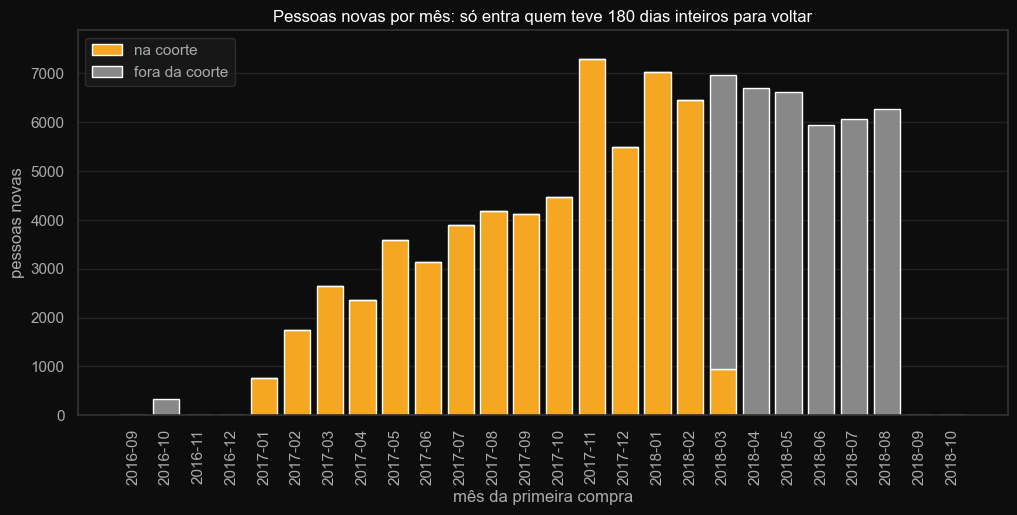

In [6]:
# pessoas novas por mês da primeira compra, separadas entre dentro e fora da coorte
# crosstab conta as pessoas em cada combinação de mês e na_coorte (True/False)
mes_primeira = pessoas['primeira_compra'].dt.to_period('M')
novas_mes = pd.crosstab(mes_primeira, na_coorte).rename(columns={True: 'na coorte', False: 'fora da coorte'})

# period_range + reindex: os meses sem nenhuma pessoa nova aparecem com 0 em vez de sumir do eixo
todos_meses = pd.period_range(mes_primeira.min(), mes_primeira.max(), freq='M')
novas_mes = novas_mes.reindex(todos_meses, fill_value=0)

# quem ficou fora: antes do período útil ou depois da data de corte
antes = pessoas['primeira_compra'] < INICIO_PERIODO_UTIL
depois_corte = pessoas['primeira_compra'] > DATA_CORTE_COORTE
print(f'fora da coorte por comprar antes de {INICIO_PERIODO_UTIL:%d/%m/%Y}: {antes.sum()} ({antes.mean():.2%} das pessoas)')
print(f'fora da coorte por comprar depois de {DATA_CORTE_COORTE:%d/%m/%Y}: {depois_corte.sum()} ({depois_corte.mean():.2%} das pessoas)')

# barras empilhadas: a coorte em laranja e o que fica fora em cinza (não entra na comparação)
fig, ax = plt.subplots()
meses_txt = novas_mes.index.astype(str)
ax.bar(meses_txt, novas_mes['na coorte'], color=CORES[2], label='na coorte')
ax.bar(meses_txt, novas_mes['fora da coorte'], bottom=novas_mes['na coorte'], color=COR_REFERENCIA,
       label='fora da coorte')
ax.set_title(f'Pessoas novas por mês: só entra quem teve {JANELA_RECOMPRA_DIAS} dias inteiros para voltar')
ax.set_xlabel('mês da primeira compra')
ax.set_ylabel('pessoas novas')
ax.tick_params(axis='x', rotation=90)
# set_ylim com 8% de folga acima do mês com mais gente nova; a legenda vai para a esquerda, onde as barras são baixas
ax.set_ylim(0, novas_mes.sum(axis=1).max() * 1.08)
ax.legend(loc='upper left')

# salvo antes do show: depois dele a figura sai da memória e a imagem ficaria em branco
plt.savefig(f'{PASTA_IMAGENS}/coorte_por_mes.png')
plt.show()

**Conclusão 2.3 — a coorte tem 58.139 pessoas, e só 2,01% delas voltaram em até 180 dias:**

**A coorte.** A data de corte é 04/03/2018. Das 96.096 pessoas da base, 58.139 (60,50%) fizeram a primeira compra entre 01/01/2017 e essa data e entram na análise. Ficam de fora 326 pessoas (0,34%) que compraram pela primeira vez antes de 2017, quando a base ainda tinha poucos pedidos, e 37.631 (39,16%) que compraram depois do corte e não tiveram os 180 dias inteiros para voltar. O gráfico mostra o custo dessa escolha: o corte tira os meses de 2018 com muita gente nova. Mesmo assim, é a única forma de comparar pessoas que tiveram o mesmo tempo para voltar.

**A recompra.** 1.167 pessoas da coorte (2,01%) fizeram outro pedido, em outro dia, até 180 dias depois da primeira compra. Essa é a taxa de referência para todos os grupos das seções 3 e 4.

**As regras da primeira compra.** 1.983 pessoas da coorte (3,41%) não tiveram nenhum pedido entregue no primeiro dia. Elas ficam na coorte e na taxa de recompra e saem só das contas de atraso. 739 pessoas (1,27%) fizeram mais de um pedido no primeiro dia, e esses pedidos contam como uma compra só. Na base inteira são 2.805 (2,92%) e 897 (0,93%), os mesmos números que o revisor encontrou.

## 2.4 Itens, avaliações e atraso (passos 5 a 7)

Junto à primeira compra de cada pessoa os itens, a nota e o atraso. `items` e `reviews` podem ter mais de uma linha por pedido, então agrego cada uma por pedido antes de juntar, senão o mesmo pedido contaria várias vezes. Dos itens, somo preço e frete e conto os itens; das avaliações, fico com a primeira respondida, a mais próxima da entrega; o atraso é a data de entrega menos a estimada, as duas sem a hora, só para pedidos entregues com data. Depois passo de pedido para pessoa com a regra da seção 1.2: preço e frete somam, a nota é a pior do dia e a compra atrasou se algum pedido atrasou. Crio o peso do frete (frete dividido pelo preço, com frete zero como frete grátis), `atrasou` e o grupo de nota: muito baixa (1), baixa (2 e 3) e alta (4 e 5).

In [7]:
def contagem_com_percentual(serie, nome='pessoas'):
    """Conta quantas linhas têm cada valor de uma coluna e o percentual sobre as linhas preenchidas.

    Parâmetros
    ----------
    serie : Series com a coluna a contar (ex.: coorte['grupo_nota']).
    nome : nome da coluna da contagem na tabela devolvida.

    Retorna
    -------
    DataFrame : uma linha por valor, com a contagem e o percentual (vazios ficam fora).
    """
    tabela = serie.value_counts().to_frame(nome)
    tabela['%'] = (tabela[nome] / tabela[nome].sum() * 100).round(2)
    return tabela


# passo 5: items tem uma linha por item; agrego por pedido antes de juntar, 
# senão o pedido se multiplica
itens_pedido = items.groupby('order_id').agg(
    preco=('price', 'sum'),
    frete=('freight_value', 'sum'),
    itens=('order_item_id', 'count'),
)

# passo 6: uma avaliação por pedido, a primeira respondida (a mais próxima da primeira entrega)
# ordeno pela data da resposta e o drop_duplicates fica com a primeira linha de cada order_id
nota_pedido = (reviews.sort_values('review_answer_timestamp')
            .drop_duplicates(subset='order_id', keep='first')
            .set_index('order_id')[['review_score']]
            .rename(columns={'review_score': 'nota'}))

# passo 7: atraso só para pedidos entregues e com data; .dt.normalize() tira a hora da entrega,
# porque a data estimada não tem hora
entregues = orders[orders['order_status'].eq('delivered') & orders['order_delivered_customer_date'].notnull()]
atraso_pedido = pd.DataFrame({
    'atraso_dias': (entregues['order_delivered_customer_date'].dt.normalize()
                    - entregues['order_estimated_delivery_date'].dt.normalize()).dt.days,
}).set_index(entregues['order_id'])
print(f"delivered sem data de entrega (fora do atraso): {(orders['order_status'].eq('delivered') & orders['order_delivered_customer_date'].isna()).sum()}")
print(f"referência, todos os pedidos entregues com data: {(atraso_pedido['atraso_dias'] > 0).sum()} "
    f"de {len(atraso_pedido)} atrasaram ({(atraso_pedido['atraso_dias'] > 0).mean():.2%})")

# os pedidos do primeiro dia das pessoas da coorte recebem itens, nota e atraso (how='left' mantém todos)
primeira_coorte = pedidos_primeiro_dia[pedidos_primeiro_dia['customer_unique_id'].isin(coorte.index)]
primeira_coorte = (primeira_coorte[['customer_unique_id', 'order_id']]
                .merge(itens_pedido, left_on='order_id', right_index=True, how='left')
                .merge(nota_pedido, left_on='order_id', right_index=True, how='left')
                .merge(atraso_pedido, left_on='order_id', right_index=True, how='left'))
print(f'pedidos do primeiro dia da coorte: {len(primeira_coorte)} linhas depois dos 3 merges '
    f"(pedidos únicos: {primeira_coorte['order_id'].nunique()})")

delivered sem data de entrega (fora do atraso): 8
referência, todos os pedidos entregues com data: 6534 de 96470 atrasaram (6.77%)


pedidos do primeiro dia da coorte: 58907 linhas depois dos 3 merges (pedidos únicos: 58907)


In [8]:
# de pedido para pessoa (regra da seção 1.2, ponto 3): preço e frete somam, a nota é a pior do dia
# e o atraso é o maior do dia, então a primeira compra atrasou se algum pedido atrasou
# dropna antes da soma: quem não tem item fica sem preço (NaN), e não com preço zero
compra_itens = (primeira_coorte.dropna(subset=['preco'])
                .groupby('customer_unique_id')[['preco', 'frete', 'itens']].sum())
compra_nota_atraso = primeira_coorte.groupby('customer_unique_id').agg(
    nota=('nota', 'min'),
    atraso_dias=('atraso_dias', 'max'),
)
coorte = coorte.join(compra_itens).join(compra_nota_atraso)
# o join deixa vazio quem não tem item, e inteiro com vazio vira decimal; 'Int64' é o inteiro do pandas que aceita vazio
coorte['itens'] = coorte['itens'].astype('Int64')

# variáveis criadas: peso do frete, atrasou e grupo de nota
coorte['peso_frete'] = coorte['frete'] / coorte['preco']
# atrasou fica vazio (<NA>) para quem não tem entrega com data; 
# 'boolean' aceita True, False e vazio
coorte['atrasou'] = (coorte['atraso_dias'] > 0).where(coorte['atraso_dias'].notnull()).astype('boolean')
# pd.cut com bins: (0, 1] = muito baixa, (1, 3] = baixa, (3, 5] = alta
coorte['grupo_nota'] = pd.cut(coorte['nota'], bins=[0, 1, 3, 5], labels=['muito baixa', 'baixa', 'alta'])

# quantas primeiras compras da coorte têm cada informação
cobertura = pd.DataFrame({
    'pessoas com a informação': [coorte['preco'].notnull().sum(), coorte['nota'].notnull().sum(),
                                coorte['atrasou'].notnull().sum()],
}, index=['itens (preço e frete)', 'avaliação (nota)', 'entrega com data (atraso)'])
cobertura['% da coorte'] = (cobertura['pessoas com a informação'] / len(coorte) * 100).round(2)
display(cobertura)

print(f"taxa de atraso na primeira compra: {coorte['atrasou'].sum()} de {coorte['atrasou'].notnull().sum()} "
    f"({coorte['atrasou'].mean():.2%})")
nota_baixa = coorte['nota'] <= 3
print(f"nota de 1 a 3 na primeira compra: {nota_baixa.sum()} de {coorte['nota'].notnull().sum()} "
    f"({nota_baixa.sum() / coorte['nota'].notnull().sum():.2%})")
print(f"frete zero (frete grátis): {(coorte['frete'] == 0).sum()} pessoas")
# sort_index mantém a ordem dos grupos do pd.cut (muito baixa, baixa, alta)
display(contagem_com_percentual(coorte['grupo_nota']).sort_index())

,pessoas com a informação,% da coorte
itens (preço e frete),57565,99.01
avaliação (nota),57643,99.15
entrega com data (atraso),56154,96.59


taxa de atraso na primeira compra: 3955 de 56154 (7.04%)
nota de 1 a 3 na primeira compra: 13989 de 57643 (24.27%)
frete zero (frete grátis): 10 pessoas


,pessoas,%
grupo_nota,,
muito baixa,7042,12.22
baixa,6947,12.05
alta,43654,75.73


**Conclusão 2.4 — quase toda a coorte tem itens, nota e entrega, e cerca de uma em cada quatro primeiras compras recebeu nota de 1 a 3 (12,22% + 12,05%):**

**Cobertura.** Das 58.139 pessoas da coorte, 57.565 (99,01%) têm itens na primeira compra, 57.643 (99,15%) têm avaliação e 56.154 (96,59%) têm entrega com data. Quem não tem uma informação sai só da pergunta que depende dela: sem item, fora do frete (c); sem nota, fora de b e e; sem entrega com data, fora de a e e. Os 3 merges mantiveram os 58.907 pedidos do primeiro dia, um por linha.

**Atraso.** 3.955 das 56.154 primeiras compras entregues com data (7,04%) chegaram depois da data estimada. Em todos os pedidos entregues da base a taxa é de 6,77% (6.534 de 96.470), então a primeira compra da coorte atrasa numa proporção parecida com a da base. Os 8 pedidos `delivered` sem data de entrega ficaram fora.

**Nota.** 13.989 das 57.643 primeiras compras avaliadas (24,27%) tiveram nota de 1 a 3. Nos grupos da H2, são 7.042 pessoas com nota muito baixa (12,22%), 6.947 com nota baixa (12,05%) e 43.654 com nota alta (75,73%).

**Frete.** Só 10 pessoas tiveram frete zero na primeira compra, e elas ficam como frete grátis.

## 2.5 Estado e base final por pessoa (passos 8 e 9)

Agrupo os estados com menos de 5% dos pedidos da base em "outros", porque estados pequenos têm poucos clientes na coorte e a taxa de recompra deles ficaria instável. O limite fica na constante `LIMITE_ESTADO`, e o estado de cada pessoa é o da primeira compra. Crio também o mês da primeira compra, que vai para o gráfico da 3.1 e para o filtro do dashboard. Por fim, confiro que a base final tem uma linha por pessoa e o mesmo número de pessoas da coorte, ou seja, que nenhum merge multiplicou linhas.

In [9]:
# limite de bom senso que o revisor aprovou também: 
# 5% dos pedidos no total (decomposição, H4): estado pequeno tem poucas pessoas que voltam, 
# a taxa fica instável, o teste perde poder e o qui-quadrado precisa de contagens mínimas; 
# os menores entram juntos em "outros"
LIMITE_ESTADO = 0.05

# passo 8: fatia de cada estado nos pedidos da base; abaixo de LIMITE_ESTADO vira "outros"
fatia_estado = pedidos['customer_state'].value_counts(normalize=True)
estados_separados = fatia_estado[fatia_estado >= LIMITE_ESTADO].index
print(f'estados com pelo menos {LIMITE_ESTADO:.0%} dos pedidos: {list(estados_separados)}')

# coorte['estado'] vem da seção 2.3: é o customer_state da primeira compra,
# guardado no agg que montou pessoas.
# where mantém o estado quando a condição é True e troca por 'outros' quando é False
coorte['grupo_estado'] = coorte['estado'].where(coorte['estado'].isin(estados_separados), 'outros')

# mês da primeira compra: filtro do dashboard e eixo do gráfico da seção 3.1
coorte['mes_primeira_compra'] = coorte['primeira_compra'].dt.to_period('M')

# passo 9: a base final tem uma linha por pessoa e o mesmo número de pessoas da coorte da seção 2.3
# revisito as seções anteriores e trago as colunas necessárias para a variavel base
colunas_base = ['customer_unique_id', 'primeira_compra', 'mes_primeira_compra', 'estado', 'grupo_estado',
            'voltou_a_comprar', 'pedidos_primeiro_dia', 'varios_pedidos_primeiro_dia', 'sem_entrega_primeiro_dia',
            'preco', 'frete', 'itens', 'peso_frete', 'nota', 'grupo_nota', 'atraso_dias', 'atrasou']
base = coorte.reset_index()[colunas_base]
print(f"linhas: {len(base)} | pessoas únicas: {base['customer_unique_id'].nunique()} | "
      f"uma linha por pessoa: {base['customer_unique_id'].is_unique}")
print(f"voltaram a comprar: {base['voltou_a_comprar'].sum()} ({base['voltou_a_comprar'].mean():.2%})")

display(contagem_com_percentual(base['grupo_estado']))

estados com pelo menos 5% dos pedidos: ['SP', 'RJ', 'MG', 'RS', 'PR']
linhas: 58139 | pessoas únicas: 58139 | uma linha por pessoa: True
voltaram a comprar: 1167 (2.01%)


,pessoas,%
grupo_estado,,
SP,23101,39.73
outros,13868,23.85
RJ,7899,13.59
MG,6978,12.00
RS,3345,5.75
PR,2948,5.07


**Conclusão 2.5 — a base final tem 58.139 pessoas, uma por linha, e 1.167 delas voltaram a comprar (2,01%):**

**Estados.** Os estados com pelo menos 5% dos pedidos são SP, RJ, MG, RS e PR, os mesmos previstos na decomposição. Na coorte, SP tem 23.101 pessoas (39,73%), RJ 7.899 (13,59%), MG 6.978 (12,00%), RS 3.345 (5,75%) e PR 2.948 (5,07%). Os demais estados somam 13.868 pessoas (23,85%) em "outros".

**Conferência.** A base tem 58.139 linhas e 58.139 pessoas únicas, o mesmo número da coorte da 2.3, então nenhum merge multiplicou linhas.

**O que a base tem.** Uma linha por pessoa com a primeira compra e o mês dela, o estado e o grupo de estado, a resposta (`voltou_a_comprar`), as duas marcações da seção 1.2 e os atributos da primeira compra: preço, frete, itens, peso do frete, nota, grupo de nota, dias de atraso e `atrasou`. É dela que saem a análise da seção 3, os testes da seção 4 e o dashboard.

---

# 3. Análise exploratória

## 3.1 Taxa de recompra da coorte e por mês da primeira compra

Calculo a taxa de recompra da coorte, que é a referência de todos os grupos daqui em diante, e vejo se ela muda conforme o mês da primeira compra. Como vou repetir a mesma conta e o mesmo gráfico em todas as perguntas, crio aqui duas funções com docstring: `tabela_recompra`, que devolve pessoas, quantas voltaram, a taxa e as diferenças em p.p. e relativa para a referência, e `plotar_recompra`, que desenha as barras com a coorte numa linha cinza. Por fim, mostro à parte a recompra de quem não teve nenhum pedido entregue no primeiro dia, como prometi na seção 1.2. Coloco aqui as funções porque novamente otimizo trabalho e continuo minha análise em cada seção específica sem escrever ainda mais código.

In [10]:
def tabela_recompra(df, coluna, referencia=None):
    """Monta a taxa de recompra de cada grupo de uma coluna e a diferença para a referência.

    Parâmetros
    ----------
    df : DataFrame com uma linha por pessoa e a coluna booleana 'voltou_a_comprar'.
    coluna : nome da coluna que define os grupos (ex.: 'atrasou', 'grupo_nota').
    referencia : rótulo do grupo de referência r (ex.: False em 'atrasou').
        Se for None, a referência é a taxa de recompra de todo o df (a coorte).

    Retorna
    -------
    DataFrame : uma linha por grupo com pessoas, voltaram, recompra_% e a diferença para a
        referência em pontos percentuais (dif_pp) e relativa (dif_relativa_%).
    """
    # groupby ignora quem está vazio na coluna; observed=True mantém só os grupos que existem
    tabela = df.groupby(coluna, observed=True)['voltou_a_comprar'].agg(
        pessoas='count', voltaram='sum')
    tabela['recompra_%'] = tabela['voltaram'] / tabela['pessoas'] * 100

    if referencia is None:
        taxa_ref = df['voltou_a_comprar'].mean() * 100
    else:
        taxa_ref = tabela.loc[referencia, 'recompra_%']

    # as duas diferenças da seção 1.1: absoluta (p.p.) e relativa (%)
    tabela['dif_pp'] = tabela['recompra_%'] - taxa_ref
    tabela['dif_relativa_%'] = tabela['dif_pp'] / taxa_ref * 100
    return tabela.round(2)


def plotar_recompra(tabela, titulo, rotulo_x, arquivo, taxa_coorte):
    """Desenha a taxa de recompra de cada grupo em barras, com a taxa da coorte como referência.

    Parâmetros
    ----------
    tabela : DataFrame devolvido por tabela_recompra (usa 'recompra_%' e 'pessoas').
    titulo : título do gráfico, escrito como conclusão.
    rotulo_x : nome do eixo x.
    arquivo : nome do .png salvo em PASTA_IMAGENS.
    taxa_coorte : taxa de recompra da coorte em %, desenhada como linha tracejada cinza.

    Retorna
    -------
    None : salva e mostra o gráfico.
    """
    fig, ax = plt.subplots()
    barras = ax.bar(tabela.index.astype(str), tabela['recompra_%'], color=COR_VOLTOU)
    # rótulo dentro da barra: a taxa e o tamanho do grupo, para não ler taxa de grupo pequeno sem cuidado
    rotulos = [f'{taxa:.2f}%\n{pessoas:,} pessoas'.replace(',', '.')
            for taxa, pessoas in zip(tabela['recompra_%'], tabela['pessoas'])]
    # ax.text no centro de cada barra, porque ax.bar_label só existe a partir do matplotlib 3.4
    for barra, rotulo in zip(barras, rotulos):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() / 2, rotulo,
                ha='center', va='center', color='#ffffff')
    ax.axhline(taxa_coorte, color=COR_REFERENCIA, linestyle='--', label=f'coorte: {taxa_coorte:.2f}%')
    ax.set_ylim(0, tabela['recompra_%'].max() * 1.3)
    ax.set_title(titulo)
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel('recompra em até 180 dias (%)')
    ax.legend(loc='upper right')
    # salvo antes do show: depois dele a figura sai da memória e a imagem ficaria em branco
    plt.savefig(f'{PASTA_IMAGENS}/{arquivo}')
    plt.show()

taxa de recompra da coorte: 1167 de 58139 (2.01%)


,pessoas,voltaram,recompra_%,dif_pp,dif_relativa_%
mes_primeira_compra,,,,,
2017-01,764,13,1.70,-0.31,-15.23
2017-02,1752,28,1.60,-0.41,-20.38
2017-03,2636,47,1.78,-0.22,-11.17
2017-04,2352,48,2.04,0.03,1.67
2017-05,3596,88,2.45,0.44,21.92
2017-06,3139,73,2.33,0.32,15.86
2017-07,3894,80,2.05,0.05,2.35
2017-08,4184,104,2.49,0.48,23.83
2017-09,4130,107,2.59,0.58,29.07


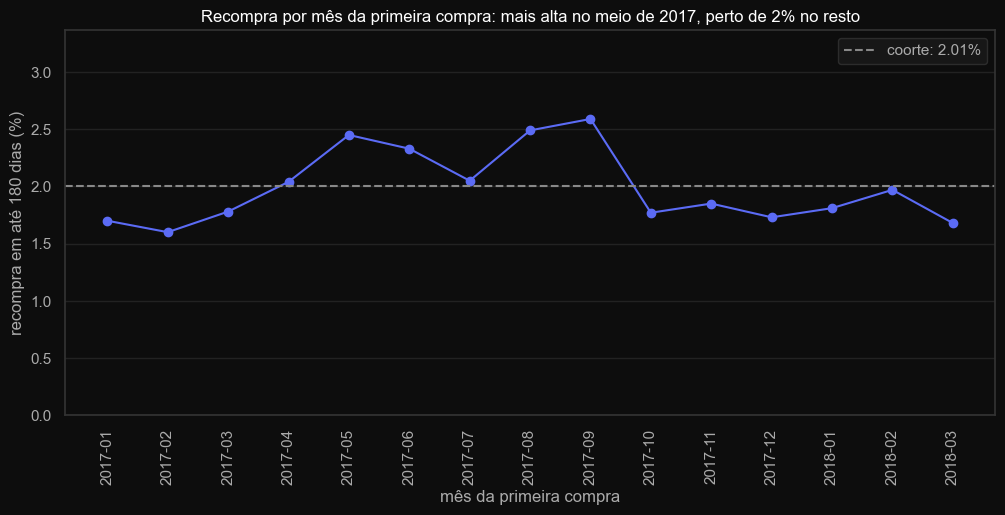

,pessoas,voltaram,recompra_%,dif_pp,dif_relativa_%
sem_entrega_primeiro_dia,,,,,
teve pedido entregue,56156,1130,2.01,0.00,0.00
nenhum pedido entregue,1983,37,1.87,-0.15,-7.28


In [11]:
# taxa da coorte: a referência de todos os grupos das seções 3 e 4
taxa_coorte = base['voltou_a_comprar'].mean() * 100
print(f"taxa de recompra da coorte: {base['voltou_a_comprar'].sum()} de {len(base)} ({taxa_coorte:.2f}%)")

# recompra por mês da primeira compra: a taxa muda ao longo do tempo?
por_mes = tabela_recompra(base, 'mes_primeira_compra')
display(por_mes)

fig, ax = plt.subplots()
ax.plot(por_mes.index.astype(str), por_mes['recompra_%'], color=COR_VOLTOU, marker='o')
ax.axhline(taxa_coorte, color=COR_REFERENCIA, linestyle='--', label=f'coorte: {taxa_coorte:.2f}%')
ax.set_title('Recompra por mês da primeira compra: mais alta no meio de 2017, perto de 2% no resto')
ax.set_xlabel('mês da primeira compra')
ax.set_ylabel('recompra em até 180 dias (%)')
ax.set_ylim(0, por_mes['recompra_%'].max() * 1.3)
ax.tick_params(axis='x', rotation=90)
ax.legend(loc='upper right')
plt.savefig(f'{PASTA_IMAGENS}/recompra_por_mes.png')
plt.show()

# quem não teve nenhum pedido entregue no primeiro dia (seção 1.2, ponto 2), à parte
display(tabela_recompra(base, 'sem_entrega_primeiro_dia', referencia=False)
        .rename(index={False: 'teve pedido entregue', True: 'nenhum pedido entregue'}))

**Conclusão 3.1 — a recompra da coorte é de 2,01% e ficou mais alta no meio de 2017:**

**A referência.** 1.167 das 58.139 pessoas da coorte (2,01%) voltaram a comprar em até 180 dias. Toda comparação das seções 3 e 4 parte desse número.

**Por mês.** A taxa vai de 1,60% (fevereiro de 2017) a 2,59% (setembro de 2017). De maio a setembro de 2017 todos os meses ficam acima da coorte, entre 2,05% e 2,59%. De outubro de 2017 a março de 2018 todos ficam abaixo, entre 1,68% e 1,97%. Os dados não dizem o motivo. Tenho duas hipóteses, que estes dados não testam. A primeira é o calendário: suponho que quem comprou no meio de 2017 tenha voltado nas épocas de promoção do fim do ano e no Natal, que caem dentro dos 180 dias. Ela tem um ponto fraco: quem comprou pela primeira vez em outubro e novembro de 2017 também tinha essas datas dentro da janela e ficou abaixo da coorte (1,77% e 1,85%). A segunda é o perfil de clientes, que pode ter mudado quando a base cresceu no fim de 2017. Março de 2018 tem só 955 pessoas, porque entram apenas os 4 primeiros dias do mês.

**Sem entrega no primeiro dia.** A recompra das 1.983 pessoas sem nenhum pedido entregue no primeiro dia é de 1,87%, contra 2,01% de quem teve pedido entregue: 0,15 p.p. a menos (7,28% abaixo). Só 37 delas voltaram, e a taxa de quem teve pedido entregue é a mesma da coorte, então mantê-las na coorte não muda a referência, aceito e sigo assim.

## 3.2 a. Atraso na primeira compra

Comparo a recompra de quem recebeu a primeira compra com atraso com a de quem recebeu no prazo, que é a referência. Só entram as 56.154 pessoas com entrega com data (seção 2.4). Mostro a tabela com as duas diferenças e o gráfico de barras com a coorte em cinza. O teste fica para a seção 4.2: aqui é só a descrição.

,pessoas,voltaram,recompra_%,dif_pp,dif_relativa_%
atrasou,,,,,
no prazo,52199,1068,2.05,0.00,0.00
com atraso,3955,62,1.57,-0.48,-23.38


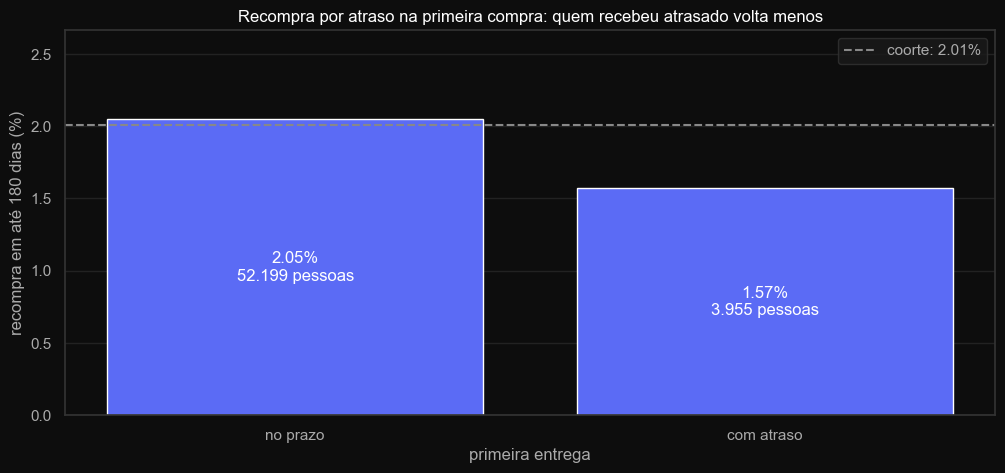

In [12]:
# só quem tem entrega com data entra (atrasou não vazio); a referência é quem recebeu no prazo
atraso = tabela_recompra(base, 'atrasou', referencia=False).rename(index={False: 'no prazo', True: 'com atraso'})
display(atraso)

plotar_recompra(atraso.loc[['no prazo', 'com atraso']],
                'Recompra por atraso na primeira compra: quem recebeu atrasado volta menos',
                'primeira entrega', 'recompra_atraso.png', taxa_coorte)

**Conclusão 3.2 — quem recebeu a primeira compra com atraso volta menos, 1,57% contra 2,05%:**

Das 3.955 pessoas com atraso, 62 voltaram (1,57%). Das 52.199 que receberam no prazo, 1.068 voltaram (2,05%). A diferença é de 0,48 p.p.: quem teve atraso volta 23,38% menos. A direção é a que a H1 esperava, mas o grupo com atraso é pequeno e só 62 pessoas dele voltaram. Se a diferença passa do acaso é o teste da seção 4.2.

## 3.3 b. Nota da primeira compra

Comparo a recompra dos três grupos de nota da primeira compra: muito baixa (1), baixa (2 e 3) e alta (4 e 5), que é a referência. Só entram as 57.643 pessoas com avaliação (seção 2.4). Uso as mesmas duas funções da 3.1.

,pessoas,voltaram,recompra_%,dif_pp,dif_relativa_%
grupo_nota,,,,,
muito baixa,7042,118,1.68,-0.42,-20.14
baixa,6947,126,1.81,-0.28,-13.56
alta,43654,916,2.10,0.00,0.00


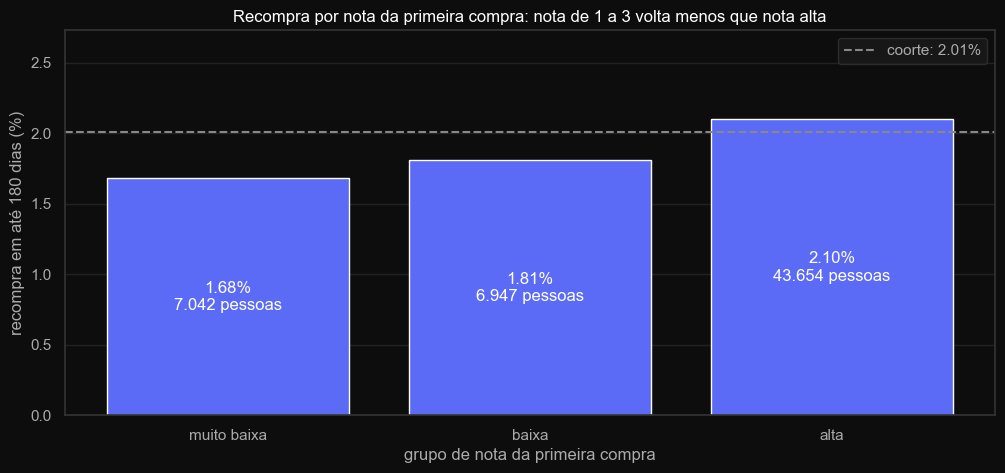

In [13]:
# a referência é a nota alta (4 e 5); 
# o pd.cut da 2.4 já deixa os grupos na ordem muito baixa, baixa, alta
nota = tabela_recompra(base, 'grupo_nota', referencia='alta')
display(nota)

plotar_recompra(nota, 'Recompra por nota da primeira compra: nota de 1 a 3 volta menos que nota alta',
                'grupo de nota da primeira compra', 'recompra_nota.png', taxa_coorte)

**Conclusão 3.3 — quanto pior a nota da primeira compra, menor a recompra:**

Com nota alta, 916 de 43.654 pessoas voltaram (2,10%). Com nota baixa, 126 de 6.947 (1,81%), 0,28 p.p. abaixo da alta (13,56% menos). Com nota muito baixa, 118 de 7.042 (1,68%), 0,42 p.p. abaixo (20,14% menos). A ordem é a que a H2 esperava: a recompra cai junto com a nota. Os testes estão na seção 4.3.

## 3.4 c. Peso do frete

Olho o peso do frete (frete dividido pelo valor dos produtos) de quem voltou e de quem não voltou. Comparo medianas e quartis, e não só a média, porque poucos pedidos com frete muito alto podem puxar a média para cima (a decomposição já tinha visto isso no preço e no frete, seção 2.3). No boxplot tiro os pontos extremos para a caixa ficar legível. Depois divido as pessoas em quartis de peso do frete com `pd.qcut` e calculo a recompra de cada um, com o quartil mais leve como referência.

,count,mean,std,min,25%,50%,75%,max
voltou_a_comprar,,,,,,,,
False,56408.0,0.304,0.291,0.00,0.132,0.223,0.371,5.739
True,1157.0,0.308,0.274,0.01,0.132,0.223,0.387,2.354


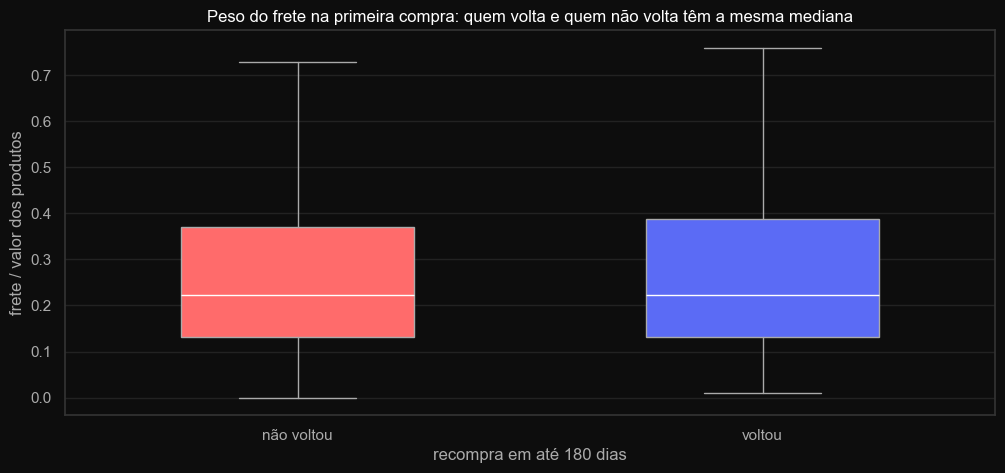

limites dos quartis do peso do frete: [0.    0.132 0.223 0.371 5.739]


,pessoas,voltaram,recompra_%,dif_pp,dif_relativa_%
faixa_frete,,,,,
Q1 (mais leve),14392,289,2.01,0.00,0.00
Q2,14393,290,2.01,0.01,0.34
Q3,14392,276,1.92,-0.09,-4.50
Q4 (mais pesado),14388,302,2.10,0.09,4.53


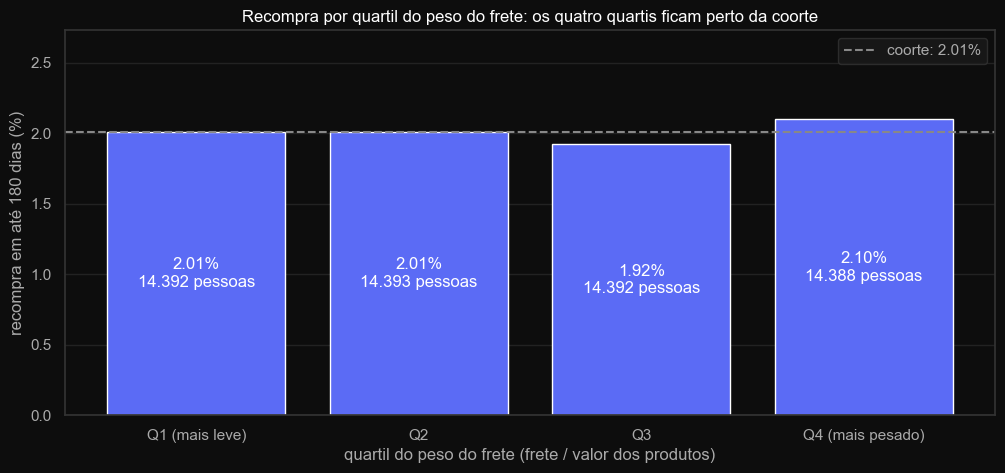

In [14]:
# peso do frete de quem voltou e de quem não voltou: a mediana resiste aos fretes muito altos
display(base.groupby('voltou_a_comprar')['peso_frete'].describe().round(3))

# testei o boxplot com os outliers: o eixo ia até perto de 6 e a caixa ficava espremida perto do zero.
# Por isso uso showfliers=False: os pontos extremos só não são desenhados, continuam nos dados e nas contas.
# Uso o boxplot do matplotlib, que funciona igual em qualquer versão do seaborn,
# aqui no VS Code e na plataforma com Jupyter
grupos_frete = [base.loc[base['voltou_a_comprar'] == voltou, 'peso_frete'].dropna() for voltou in [False, True]]
fig, ax = plt.subplots()
caixas = ax.boxplot(grupos_frete, showfliers=False, patch_artist=True, widths=0.5,
                    medianprops={'color': '#ffffff'}, boxprops={'edgecolor': '#aaaaaa'}, whiskerprops={'color': '#aaaaaa'}, capprops={'color': '#aaaaaa'})
for caixa, cor in zip(caixas['boxes'], [COR_NAO_VOLTOU, COR_VOLTOU]):
    caixa.set_facecolor(cor)
ax.set_xticks([1, 2])
ax.set_xticklabels(['não voltou', 'voltou'])
ax.set_title('Peso do frete na primeira compra: quem volta e quem não volta têm a mesma mediana')
ax.set_xlabel('recompra em até 180 dias')
ax.set_ylabel('frete / valor dos produtos')
plt.savefig(f'{PASTA_IMAGENS}/frete_boxplot.png')
plt.show()

# pd.qcut corta pela quantidade de pessoas, e não por limites que eu escolho 
# (como o pd.cut da nota, na 2.4):
# q=4 acha os limites que deixam 1/4 das pessoas em cada faixa, os quartis,
# porque o frete não tem um limite natural de "pesado"
# retbins=True devolve também esses limites, que guardo em 'limites' para saber onde cada 
# quartil começa e termina.
base['faixa_frete'], limites = pd.qcut(base['peso_frete'], q=4, retbins=True,
                                    labels=['Q1 (mais leve)', 'Q2', 'Q3', 'Q4 (mais pesado)'])
print('limites dos quartis do peso do frete:', limites.round(3))

# a referência é o quartil mais leve: a pergunta c é se o frete pesado afasta
frete = tabela_recompra(base, 'faixa_frete', referencia='Q1 (mais leve)')
display(frete)

plotar_recompra(frete, 'Recompra por quartil do peso do frete: os quatro quartis ficam perto da coorte',
                'quartil do peso do frete (frete / valor dos produtos)', 'recompra_frete_quartil.png', taxa_coorte)

**Conclusão 3.4 — o peso do frete não separa quem volta de quem não volta:**

**Assimetria.** O peso do frete é assimétrico: a média (0,304 para quem não voltou e 0,308 para quem voltou) fica acima da mediana (0,223), e o máximo chega a 5,739, um frete quase 6 vezes maior que o valor dos produtos. Por isso leio medianas e quartis.

**Medianas.** O peso do frete mediano é 0,223 nos dois grupos: o frete equivale a cerca de 22% do valor dos produtos tanto para as 1.157 pessoas que voltaram quanto para as 56.408 que não voltaram. O 1º e o 3º quartis também quase coincidem (0,132 e 0,387 para quem voltou, 0,132 e 0,371 para quem não voltou).

**Quartis.** A recompra fica entre 1,92% e 2,10% nos quatro quartis. O quartil mais pesado, em que o frete passa de 0,371 do valor dos produtos, tem 2,10%, 0,09 p.p. acima do mais leve (4,53% a mais). A descrição não mostra o padrão que a H3 esperava. O Mann-Whitney da seção 4.5 confere se há alguma diferença na distribuição.

## 3.5 d. Estado do cliente

Comparo a recompra de cada grupo de estado (SP, RJ, MG, RS, PR e "outros") com a taxa da coorte, da maior para a menor. O estado é o da primeira compra (seção 2.3).

,pessoas,voltaram,recompra_%,dif_pp,dif_relativa_%
grupo_estado,,,,,
SP,23101,519,2.25,0.24,11.93
RJ,7899,165,2.09,0.08,4.07
MG,6978,132,1.89,-0.12,-5.76
RS,3345,62,1.85,-0.15,-7.66
outros,13868,241,1.74,-0.27,-13.42
PR,2948,48,1.63,-0.38,-18.88


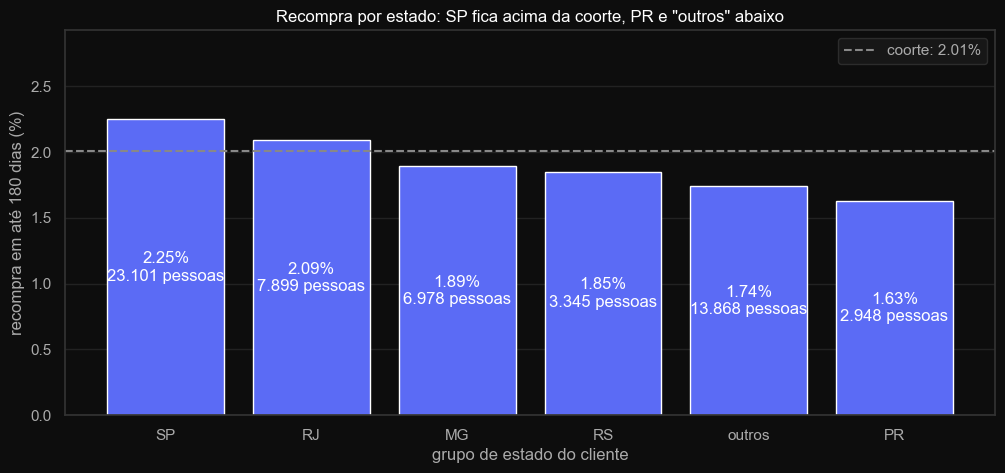

In [15]:
# a referência é a coorte; sort_values ordena da maior para a menor recompra
estado = tabela_recompra(base, 'grupo_estado').sort_values('recompra_%', ascending=False)
display(estado)

plotar_recompra(estado, 'Recompra por estado: SP fica acima da coorte, PR e "outros" abaixo',
                'grupo de estado do cliente', 'recompra_estado.png', taxa_coorte)

**Conclusão 3.5 — SP e RJ ficam acima da coorte; MG, RS, "outros" e PR, abaixo:**

SP tem a maior recompra, 2,25% (519 de 23.101 pessoas), 0,24 p.p. acima da coorte (11,93% a mais), seguido de RJ, com 2,09% (4,07% acima). Abaixo da coorte estão MG (1,89%), RS (1,85%), "outros" (1,74%, 13,42% abaixo) e PR, com a menor taxa: 1,63% (48 de 2.948), 0,38 p.p. abaixo (18,88% a menos). As diferenças são de décimos de ponto e os grupos de RS e PR são pequenos, então a seção 4.6 testa se elas passam do acaso. Suponho que SP vá melhor por estar perto da maior parte dos lojistas e ter entrega mais rápida, mas isso não está nestes dados, é apenas suposição, por termos dois grandes centros do país no RJ e SP.

## 3.6 e. Atraso e nota juntos

A pergunta e é se o atraso afasta o cliente por derrubar a nota. Faço em duas partes. Primeiro, com `pd.crosstab`, comparo a proporção de nota de 1 a 3 entre quem recebeu no prazo e quem recebeu com atraso. Depois, num laço pelos três grupos de nota, comparo a recompra com e sem atraso dentro do mesmo grupo: se o atraso continuar pesando com a nota igual, a nota não explica tudo. Nas barras agrupadas, no prazo fica em cinza (referência) e com atraso em roxo, uma cor que não se confunde com voltou e não voltou.

,nota 4 e 5 (%),nota 1 a 3 (%)
primeira entrega,,
no prazo,81.83,18.17
com atraso,24.37,75.63


pessoas  voltaram  recompra_%  dif_pp  dif_relativa_%
grupo_nota  atrasou                                                          
muito baixa no prazo       3476        66        1.90    0.00            0.00
            com atraso     2192        33        1.51   -0.39          -20.71
baixa       no prazo       5952       110        1.85    0.00            0.00
            com atraso      729        13        1.78   -0.06           -3.51
alta        no prazo      42447       887        2.09    0.00            0.00
            com atraso      941        16        1.70   -0.39          -18.63

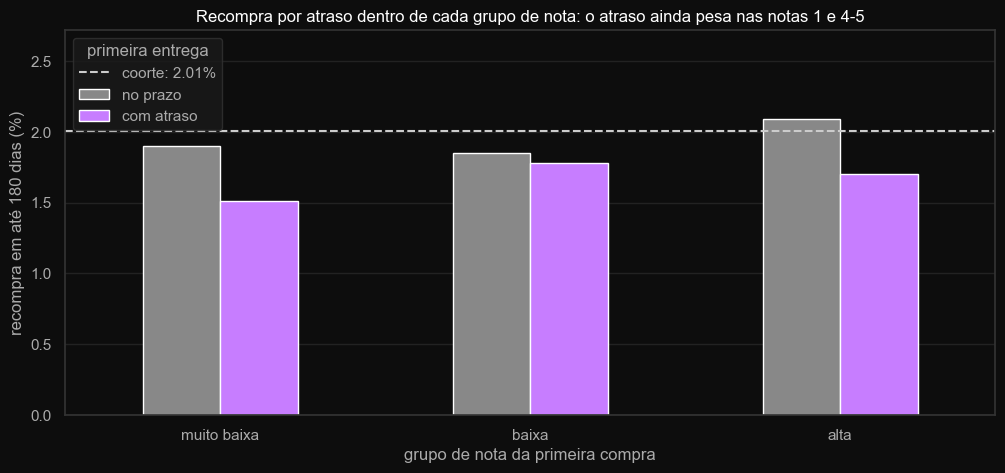

In [16]:
COR_COM_ATRASO = '#C77DFF'    # roxo: atraso na primeira compra (o cinza fica para no prazo)

# parte 1: o atraso derruba a nota? proporção de nota de 1 a 3 em cada grupo de atraso
# crosstab com normalize='index' devolve a proporção dentro de cada linha (cada grupo de atraso)
com_nota_e_entrega = base[base['nota'].notnull() & base['atrasou'].notnull()]
nota_por_atraso = pd.crosstab(com_nota_e_entrega['atrasou'], com_nota_e_entrega['nota'] <= 3,
                            normalize='index').mul(100).round(2)
nota_por_atraso = nota_por_atraso.rename(index={False: 'no prazo', True: 'com atraso'},
                                        columns={False: 'nota 4 e 5 (%)', True: 'nota 1 a 3 (%)'})
nota_por_atraso = nota_por_atraso.rename_axis(index='primeira entrega', columns=None)
display(nota_por_atraso)

# parte 2: dentro do mesmo grupo de nota, o atraso ainda muda a recompra?
# laço: a mesma tabela para cada grupo de nota, com quem recebeu no prazo como referência
partes = []
for grupo in base['grupo_nota'].cat.categories:
    no_grupo = base[base['grupo_nota'] == grupo]
    parte = tabela_recompra(no_grupo, 'atrasou', referencia=False).rename(index={False: 'no prazo', True: 'com atraso'})
    parte['grupo_nota'] = grupo
    partes.append(parte)
atraso_dentro_nota = pd.concat(partes).reset_index().set_index(['grupo_nota', 'atrasou'])
display(atraso_dentro_nota)

# barras agrupadas: x = grupo de nota, uma barra para no prazo e outra para com atraso
# unstack ordena os grupos em ordem alfabética; o reindex volta para muito baixa, baixa, alta
grafico = (atraso_dentro_nota['recompra_%'].unstack('atrasou')
        .reindex(base['grupo_nota'].cat.categories)[['no prazo', 'com atraso']])
fig, ax = plt.subplots()
grafico.plot(kind='bar', color=[COR_REFERENCIA, COR_COM_ATRASO], ax=ax, rot=0)
ax.axhline(taxa_coorte, color='#cccccc', linestyle='--', label=f'coorte: {taxa_coorte:.2f}%')
ax.set_title('Recompra por atraso dentro de cada grupo de nota: o atraso ainda pesa nas notas 1 e 4-5')
ax.set_xlabel('grupo de nota da primeira compra')
ax.set_ylabel('recompra em até 180 dias (%)')
ax.set_ylim(0, grafico.max().max() * 1.3)
ax.grid(axis='x', visible=False)
ax.legend(title='primeira entrega', loc='upper left')
plt.savefig(f'{PASTA_IMAGENS}/atraso_dentro_nota.png')
plt.show()

**Conclusão 3.6 — o atraso derruba a nota, e mesmo com a nota igual quem teve atraso volta menos em dois dos três grupos:**

**O atraso derruba a nota.** Entre quem recebeu com atraso, 75,63% deram nota de 1 a 3. Entre quem recebeu no prazo, 18,17%. É a maior diferença da seção 3.

**Com a mesma nota.** Na nota muito baixa, a recompra com atraso é de 1,51% contra 1,90% no prazo (20,71% menos). Na nota alta, 1,70% contra 2,09% (18,63% menos). Na nota baixa os dois quase empatam: 1,78% contra 1,85% (3,51% menos). Então a nota não explica tudo, porque em dois dos três grupos o atraso continua ligado a uma recompra menor.

**Cuidado.** Os grupos com atraso são pequenos dentro de cada nota: 33 pessoas voltaram na nota muito baixa, 13 na baixa e 16 na alta. Essas diferenças podem ser acaso, e a seção 4.4 (H5) testa cada uma com a correção de Holm.

---

# 4. Validação das hipóteses

## 4.1 Regras e funções dos testes

Antes de qualquer teste, fixo as regras e escrevo as funções que vou usar em todas as hipóteses, mesmo pafdrão que prefiro de organização. `ALFA = 0.05` é o nível de significância, decidido aqui e não depois de ver os p-valores. O teste z de duas proporções serve para H1, H2, H4 e H5 porque a resposta é binária (voltou ou não) e cada pessoa está em um grupo só. Além do p-valor, a função devolve a diferença em p.p. e relativa e o intervalo de 95% da diferença, porque o revisor pediu o tamanho do efeito junto. Também calculo a menor diferença que o teste detecta com 80% de poder: como pouca gente volta, um "não rejeito H0" pode ser só falta de tamanho, e esse número mostra quando é o caso. Quando uma hipótese tem mais de uma comparação, uso a correção de Holm, que escrevi como função e confiro com um exemplo pequeno.

In [17]:
ALFA = 0.05     # nível de significância, decidido antes de rodar qualquer teste
PODER = 0.80    # poder que uso para calcular a menor diferença que o teste consegue ver


def teste_z_proporcoes(sucessos_g, n_g, sucessos_r, n_r):
    """Teste z bicaudal de duas proporções entre o grupo g e o grupo de referência r.

    Parâmetros
    ----------
    sucessos_g, n_g : quantos do grupo g tiveram o evento (ex.: voltaram) e o tamanho do grupo.
    sucessos_r, n_r : o mesmo para o grupo de referência r.

    Retorna
    -------
    dict : taxas em %, diferença em p.p. e relativa (%), intervalo de 95% da diferença em p.p.,
        estatística z e p-valor.
    """
    taxa_g = sucessos_g / n_g
    taxa_r = sucessos_r / n_r
    # sob H0 os dois grupos têm a mesma taxa, então o erro usa a proporção dos dois juntos
    taxa_comb = (sucessos_g + sucessos_r) / (n_g + n_r)
    # relembro e trago aqui a fórmula
    erro = np.sqrt(taxa_comb * (1 - taxa_comb) * (1 / n_g + 1 / n_r))
    z = (taxa_g - taxa_r) / erro
    # sf é a área da cauda; multiplico por 2 porque o teste é bicaudal
    p_valor = 2 * stats.norm.sf(abs(z))

    # o intervalo não supõe H0, então uso o erro de cada grupo separado
    erro_ic = np.sqrt(taxa_g * (1 - taxa_g) / n_g + taxa_r * (1 - taxa_r) / n_r)
    margem = stats.norm.ppf(1 - ALFA / 2) * erro_ic
    dif = taxa_g - taxa_r
    return {
        'taxa_g_%': taxa_g * 100, 'taxa_r_%': taxa_r * 100,
        'dif_pp': dif * 100, 'dif_relativa_%': dif / taxa_r * 100,
        'ic95_inf_pp': (dif - margem) * 100, 'ic95_sup_pp': (dif + margem) * 100,
        'z': z, 'p_valor': p_valor,
    }


def menor_diferenca_detectavel(taxa_r, n_g, n_r):
    """Calcula a menor diferença (em p.p.) que o teste z detecta com o PODER e o ALFA definidos.

    Parâmetros
    ----------
    taxa_r : taxa do grupo de referência, entre 0 e 1.
    n_g, n_r : tamanhos dos dois grupos.

    Retorna
    -------
    float : diferença mínima em pontos percentuais. Uma diferença real menor que essa
        tem boa chance de não dar significativa.
    """
    erro = np.sqrt(taxa_r * (1 - taxa_r) * (1 / n_g + 1 / n_r))
    return (stats.norm.ppf(1 - ALFA / 2) + stats.norm.ppf(PODER)) * erro * 100


def comparar_grupos(df, coluna, grupo, referencia, resposta='voltou_a_comprar'):
    """Separa o grupo g e a referência r de uma coluna e roda o teste z na coluna de resposta.

    Parâmetros
    ----------
    df : DataFrame com uma linha por pessoa.
    coluna : coluna que define os grupos (ex.: 'atrasou').
    grupo, referencia : rótulos do grupo g e do grupo r nessa coluna (ex.: True e False).
    resposta : coluna booleana do evento contado (padrão: 'voltou_a_comprar').

    Retorna
    -------
    dict : rótulos, tamanhos, quantos tiveram o evento, o resultado de teste_z_proporcoes
        e a menor diferença detectável.
    """
    # eq + fillna(False): quem está vazio na coluna não entra em nenhum dos dois grupos
    g = df.loc[df[coluna].eq(grupo).fillna(False), resposta]
    r = df.loc[df[coluna].eq(referencia).fillna(False), resposta]
    resultado = teste_z_proporcoes(g.sum(), len(g), r.sum(), len(r))
    return {'grupo': grupo, 'referencia': referencia, 'n_g': len(g), 'eventos_g': g.sum(),
            'n_r': len(r), 'eventos_r': r.sum(), **resultado,
            'menor_dif_detectavel_pp': menor_diferenca_detectavel(r.mean(), len(g), len(r))}


def corrigir_holm(p_valores):
    """Aplica a correção de Holm aos p-valores das comparações de uma mesma hipótese.

    Parâmetros
    ----------
    p_valores : lista ou Series com os p-valores das comparações.

    Retorna
    -------
    ndarray : p-valores ajustados, na mesma ordem da entrada. Comparo cada um com ALFA.
    """
    # asarray transforma lista ou coluna do pandas em array do numpy: assim p[indice]
    #  busca pela posição (numa coluna do pandas buscaria pelo rótulo do índice, como 
    # 'muito baixa' na 4.4)
    p = np.asarray(p_valores, dtype=float)
    m = len(p)
    ajustados = np.empty(m)
    maior_ate_aqui = 0
    # do menor para o maior p-valor: o menor é multiplicado por m, o seguinte por m - 1,
    #  e assim por diante
    for posicao, indice in enumerate(np.argsort(p)):
        valor = min((m - posicao) * p[indice], 1)
        # o ajustado nunca pode ficar menor que o anterior
        maior_ate_aqui = max(maior_ate_aqui, valor)
        ajustados[indice] = maior_ate_aqui
    return ajustados


def veredito(p_valor):
    """Devolve a decisão ('rejeito H0' ou 'não rejeito H0') para um p-valor comparado com ALFA."""
    return 'rejeito H0' if p_valor < ALFA else 'não rejeito H0'


# confiro a função de Holm com um exemplo pequeno que dá para fazer de cabeça:
# 0.01 x 3 = 0.03 | 0.03 x 2 = 0.06 | 0.04 x 1 = 0.04, que sobe para 0.06 para não ficar menor que o anterior
print('Holm de [0.01, 0.04, 0.03]:', corrigir_holm([0.01, 0.04, 0.03]).round(2))
print(f'ALFA = {ALFA} | PODER = {PODER}')

Holm de [0.01, 0.04, 0.03]: [0.03 0.06 0.06]
ALFA = 0.05 | PODER = 0.8


**Conclusão 4.1 — as regras valem para todos os testes da seção 4:**

O nível de significância é 5% e o poder de referência é 80%, os dois em constantes. Cada teste z devolve as taxas dos dois grupos, a diferença em p.p. e relativa, o intervalo de 95% da diferença, o z e o p-valor, além da menor diferença detectável. A função de Holm devolveu [0,03 0,06 0,06] para o exemplo [0,01 0,04 0,03], o mesmo resultado da conta à mão, então ela está certa. Os dados são observacionais: um resultado significativo mostra que o fator anda junto com a recompra, não que ele a causa.

**Como montei as funções.** Escrevi estas funções com apoio do copilot e claude, pois eram muitas para recordar e acertar exatamente, estudei cada etapa antes de usar: pesquisei como o teste z de duas proporções calcula o erro, por que o intervalo de 95% usa um erro diferente do teste, o que é o poder de um teste e como a correção de Holm ordena e ajusta os p-valores. Procurei entender como cada parte serve a este projeto, em que pouca gente volta e por isso o tamanho do efeito e o poder importam tanto quanto o p-valor. Conferi a função de Holm com um exemplo que fiz à mão.

## 4.2 H1: atraso na primeira compra reduz a recompra

H0: a recompra de quem teve atraso na primeira compra é igual à de quem recebeu no prazo. H1: é diferente. Uso o teste z de proporções entre as 56.154 pessoas com entrega com data (seção 2.4), com quem recebeu no prazo como referência.

In [18]:
# legenda das colunas das tabelas de teste (vale para toda a seção 4):
#   g = grupo analisado | r = grupo de referência
#   n_g, n_r = tamanho de cada grupo | eventos_g, eventos_r = quantos tiveram o evento (voltaram)

#   taxa_g_%, taxa_r_% = taxa de cada grupo em % 
#   | dif_pp = taxa_g - taxa_r em pontos percentuais

#   dif_relativa_% = dif_pp dividida pela taxa_r, em %

#   ic95_inf_pp, ic95_sup_pp = limites de baixo e de cima do intervalo de confiança 
#   de 95% da diferença, em p.p.
#   
#   z = estatística do teste | p_valor = p-valor bicaudal
#   menor_dif_detectavel_pp = menor diferença que o teste vê com 80% de poder
#   p_holm = p-valor ajustado por Holm (4.3, 4.4 e 4.6) | decisao = rejeito ou não rejeito H0

# H1: g = quem teve atraso, r = quem recebeu no prazo (só pessoas com entrega com data)

h1 = comparar_grupos(base, 'atrasou', True, False)
display(pd.DataFrame([h1]).set_index('grupo').round(3))

print(f"p-valor = {h1['p_valor']:.4f} -> {veredito(h1['p_valor'])} (ALFA = {ALFA})")
print(f"diferença: {h1['dif_pp']:.2f} p.p. ({h1['dif_relativa_%']:.1f}%), "
      f"intervalo de 95%: {h1['ic95_inf_pp']:.2f} a {h1['ic95_sup_pp']:.2f} p.p.")
print(f"menor diferença que o teste detecta com {PODER:.0%} de poder: {h1['menor_dif_detectavel_pp']:.2f} p.p.")

,referencia,n_g,eventos_g,n_r,eventos_r,taxa_g_%,taxa_r_%,dif_pp,dif_relativa_%,ic95_inf_pp,ic95_sup_pp,z,p_valor,menor_dif_detectavel_pp
grupo,,,,,,,,,,,,,,
True,False,3955,62,52199,1068,1.568,2.046,-0.478,-23.381,-0.884,-0.073,-2.066,0.039,0.654


p-valor = 0.0389 -> rejeito H0 (ALFA = 0.05)
diferença: -0.48 p.p. (-23.4%), intervalo de 95%: -0.88 a -0.07 p.p.
menor diferença que o teste detecta com 80% de poder: 0.65 p.p.


**Conclusão 4.2 — rejeito H0: quem teve atraso na primeira compra volta menos, mas o resultado está no limite:**

**O teste.** A recompra de quem teve atraso é de 1,568% (62 de 3.955) contra 2,046% de quem recebeu no prazo (1.068 de 52.199). O z é −2,066 e o p-valor é 0,0389, abaixo do ALFA de 0,05, então rejeito H0.

**O tamanho.** A diferença é de 0,48 p.p., ou seja, quem teve atraso volta 23,4% menos. O intervalo de 95% vai de −0,88 a −0,07 p.p.: o efeito pode ser bem pequeno, mas fica do lado negativo.

**O limite.** A menor diferença que o teste detecta com 80% de poder é 0,65 p.p., maior que a diferença observada. O grupo com atraso é pequeno, e o p-valor ficou perto do ALFA. A seção 4.7 mostra se o resultado se mantém com outras janelas.

**Para a logística.** O atraso na primeira entrega anda junto com menos recompra. Como os dados são observacionais, isso não prova que entregar no prazo traria o cliente de volta, mas aponta o prazo como um lugar para agir.

## 4.3 H2: nota baixa na primeira compra reduz a recompra

H0: a recompra é igual nos três grupos de nota. H1: pelo menos um grupo é diferente. Primeiro faço o qui-quadrado nos três grupos, porque com mais de dois grupos ele testa tudo de uma vez e evita comparações sem necessidade. Só se ele rejeitar H0, comparo cada grupo de nota baixa com a nota alta pelo teste z, com Holm para as 2 comparações.

In [19]:
# etapa 1: qui-quadrado nos três grupos de nota (H0: a recompra é igual nos três)
tabela_nota = pd.crosstab(base['grupo_nota'], base['voltou_a_comprar'])
display(tabela_nota)
# chi2_contingency recebe a tabela cruzada (grupo de nota x voltou) e devolve 4 coisas, 
# nesta ordem: a estatística qui-quadrado, o p-valor, os graus de liberdade 
# ((3 linhas - 1) x (2 colunas - 1) = 2)
# e a tabela de contagens esperadas, que é quanto cada célula teria se a recompra fosse igual 
# nas três notas
qui2, p_qui2, gl, esperados = stats.chi2_contingency(tabela_nota)
print(f'qui-quadrado = {qui2:.2f} | gl = {gl} | p-valor = {p_qui2:.4f} -> {veredito(p_qui2)}')
# o qui-quadrado pede pelo menos 5 casos esperados em cada célula
print(f'menor contagem esperada: {esperados.min():.1f}')

voltou_a_comprar,False,True
grupo_nota,,
muito baixa,6924,118
baixa,6821,126
alta,42738,916


qui-quadrado = 7.07 | gl = 2 | p-valor = 0.0291 -> rejeito H0
menor contagem esperada: 139.8


In [20]:
# etapa 2: só se a etapa 1 rejeitar H0, cada nota baixa contra a alta, 
# com Holm para as 2 comparações
if p_qui2 < ALFA:
    h2 = pd.DataFrame([comparar_grupos(base, 'grupo_nota', grupo, 'alta') for grupo in ['muito baixa', 'baixa']])
    h2['p_holm'] = corrigir_holm(h2['p_valor'])
    h2['decisao'] = h2['p_holm'].apply(veredito)
    display(h2.set_index('grupo').round(4))
else:
    print('não rejeito H0 no qui-quadrado, então não faço as comparações dois a dois')

,referencia,n_g,eventos_g,n_r,eventos_r,taxa_g_%,taxa_r_%,dif_pp,dif_relativa_%,ic95_inf_pp,ic95_sup_pp,z,p_valor,menor_dif_detectavel_pp,p_holm,decisao
grupo,,,,,,,,,,,,,,,,
muito baixa,alta,7042,118,43654,916,1.6757,2.0983,-0.4227,-20.1427,-0.7512,-0.0941,-2.3284,0.0199,0.5157,0.0398,rejeito H0
baixa,alta,6947,126,43654,916,1.8137,2.0983,-0.2846,-13.5626,-0.6260,0.0568,-1.5513,0.1208,0.5187,0.1208,não rejeito H0


**Conclusão 4.3 — rejeito H0: a nota da primeira compra muda a recompra, e a diferença está na nota 1:**

**Qui-quadrado.** Nos três grupos de nota, o qui-quadrado é 7,07 com 2 graus de liberdade e p-valor 0,0291: rejeito H0, a recompra não é igual nos três grupos. A menor contagem esperada é 139,8, bem acima de 5, então o teste vale.

**Nota muito baixa contra alta.** 1,676% contra 2,098%, uma diferença de 0,42 p.p. (20,1% a menos). O p-valor ajustado por Holm é 0,0398: rejeito H0.

**Nota baixa contra alta.** 1,814% contra 2,098%, 0,28 p.p. a menos (13,6%). O p-valor ajustado é 0,1208: não rejeito H0. O intervalo de 95% vai de −0,63 a +0,06 p.p. e a menor diferença detectável é 0,52 p.p., então o teste não tem tamanho para ver uma diferença dessas.

**Para o pós-venda.** A nota 1 é o sinal mais claro de cliente que não volta. Faz sentido o pós-venda agir primeiro em quem dá nota 1, talvez automatizar respostas ou campanhas pra tais clientes. 

## 4.4 H5: o atraso reduz a recompra porque derruba a nota

A H5 diz que o atraso reduz a recompra porque derruba a nota. Testo em duas partes. Parte 1: H0 é que a proporção de nota de 1 a 3 é igual com e sem atraso (teste z). Parte 2: H0 é que, dentro de cada grupo de nota, a recompra com atraso é igual à recompra no prazo (teste z em cada grupo, num laço, com Holm para as 3 comparações). Se o atraso derrubar a nota e o efeito dele sumir quando a nota é a mesma, é a nota que explica a volta.

In [21]:
# parte 1: o atraso derruba a nota? (H0: a proporção de nota de 1 a 3 é igual com e sem atraso)
com_nota_e_entrega = base[base['nota'].notnull() & base['atrasou'].notnull()].copy()
com_nota_e_entrega['nota_baixa'] = com_nota_e_entrega['nota'] <= 3
h5_parte1 = comparar_grupos(com_nota_e_entrega, 'atrasou', True, False, resposta='nota_baixa')
print(f"nota de 1 a 3: com atraso {h5_parte1['taxa_g_%']:.2f}% x no prazo {h5_parte1['taxa_r_%']:.2f}% | "
    f"diferença {h5_parte1['dif_pp']:.2f} p.p.")
print(f"z = {h5_parte1['z']:.2f} | p-valor = {h5_parte1['p_valor']} -> {veredito(h5_parte1['p_valor'])}")

# parte 2: com a nota igual, o atraso ainda muda a recompra? (Holm para as 3 comparações)
# laço pelos grupos de nota: se o efeito do atraso some dentro de cada nota, 
# é a nota que explica a volta
linhas = []
for grupo in base['grupo_nota'].cat.categories:
    no_grupo = base[base['grupo_nota'] == grupo]
    linha = comparar_grupos(no_grupo, 'atrasou', True, False)
    linha['grupo_nota'] = grupo
    linhas.append(linha)
h5_parte2 = pd.DataFrame(linhas).set_index('grupo_nota')
h5_parte2['p_holm'] = corrigir_holm(h5_parte2['p_valor'])
h5_parte2['decisao'] = h5_parte2['p_holm'].apply(veredito)
# trago de volta as informações detalhadas por grupo de nota, consultando os nomes anteriormente
display(h5_parte2[['n_g', 'eventos_g', 'n_r', 'eventos_r', 'taxa_g_%', 'taxa_r_%', 'dif_pp', 'dif_relativa_%',
                'ic95_inf_pp', 'ic95_sup_pp', 'p_valor', 'p_holm', 'decisao', 'menor_dif_detectavel_pp']].round(3))

nota de 1 a 3: com atraso 75.63% x no prazo 18.17% | diferença 57.46 p.p.
z = 82.95 | p-valor = 0.0 -> rejeito H0


,n_g,eventos_g,n_r,eventos_r,taxa_g_%,taxa_r_%,dif_pp,dif_relativa_%,ic95_inf_pp,ic95_sup_pp,p_valor,p_holm,decisao,menor_dif_detectavel_pp
grupo_nota,,,,,,,,,,,,,,
muito baixa,2192,33,3476,66,1.505,1.899,-0.393,-20.712,-1.076,0.289,0.271,0.813,não rejeito H0,1.043
baixa,729,13,5952,110,1.783,1.848,-0.065,-3.509,-1.085,0.955,0.902,0.902,não rejeito H0,1.481
alta,941,16,42447,887,1.700,2.090,-0.389,-18.632,-1.227,0.448,0.408,0.816,não rejeito H0,1.321


**Conclusão 4.4 — o atraso derruba a nota, mas os dados não têm tamanho para dizer se é só pela nota que ele afasta o cliente:**

**Parte 1, o atraso e a nota.** Entre quem teve atraso, 75,63% deram nota de 1 a 3, contra 18,17% de quem recebeu no prazo: 57,46 p.p. a mais. O z é 82,95 e o p-valor sai como 0,0. Fui entender por que ele dá exatamente zero: o p-valor não é zero, é um número tão pequeno que fica abaixo do menor valor que o Python consegue guardar, e por isso é gravado como 0,0. Rejeito H0. É o resultado mais forte do projeto.

**Parte 2, com a mesma nota.** Dentro de cada grupo de nota, quem teve atraso volta menos na nota muito baixa (−0,39 p.p.) e na alta (−0,39 p.p.), e quase igual na baixa (−0,07 p.p.). Mas nenhum p-valor ajustado por Holm fica abaixo de 0,05 (0,813, 0,902 e 0,816), e não rejeito H0 em nenhum grupo.

**Por que não dá para fechar a H5.** Os grupos com atraso são pequenos dentro de cada nota (33, 13 e 16 pessoas voltaram), e a menor diferença detectável vai de 1,04 a 1,48 p.p., mais que o dobro das diferenças observadas. Não rejeitar H0 aqui não prova que o efeito do atraso some com a nota: o teste não tem tamanho para ver. Uma regressão logística com atraso e nota juntos, que o revisor deixou como opcional, também não resolveria: o atraso e a nota andam tão juntos (75,63% de nota de 1 a 3 com atraso, contra 18,17% no prazo, na parte 1) que nenhum modelo com estes dados consegue dizer qual dos dois afasta o cliente. Por isso fico com o que os dados sustentam: o atraso derruba a nota, e a nota 1 reduz a recompra (seção 4.3).

**O que vem primeiro para a Olist.** O atraso derruba a nota com muita força, e a nota 1 reduz a recompra (seção 4.3). Isso aponta para a entrega antes do pós-venda: evitar o atraso evita boa parte das notas baixas.

## 4.5 H3: frete pesado reduz a recompra

H0: o peso do frete na primeira compra tem a mesma distribuição para quem volta e para quem não volta. H1: é diferente. Uso o Mann-Whitney porque ele compara as distribuições sem supor que são normais. Como tamanho do efeito, transformo a estatística U na chance de uma pessoa que voltou ter o frete mais pesado que uma que não voltou, em que 0,5 quer dizer nenhuma diferença.

In [22]:
# Mann-Whitney: compara as distribuições sem supor normal, porque o peso do frete é
# assimétrico (seção 3.4)
frete_voltou = base.loc[base['voltou_a_comprar'], 'peso_frete'].dropna()
frete_nao_voltou = base.loc[~base['voltou_a_comprar'], 'peso_frete'].dropna()

# mannwhitneyu junta os dois grupos, ordena todos os pesos do frete e compara 
# as posições de cada grupo;
# devolve 2 coisas: U (quantas vezes alguém que voltou fica à frente de alguém que não voltou) 
# e o p-valor alternative='two-sided' = bicaudal, porque a H1 diz só "é diferente",
# sem dizer para que lado
u, p_mw = stats.mannwhitneyu(frete_voltou, frete_nao_voltou, alternative='two-sided')

print(f'medianas do peso do frete: voltou {frete_voltou.median():.3f} | não voltou {frete_nao_voltou.median():.3f}')
print(f'U = {u:.0f} | p-valor = {p_mw:.4f} -> {veredito(p_mw)}')

# tamanho do efeito: U dividido pelo número de pares possíveis é a chance de alguém que voltou
# ter o frete mais pesado que alguém que não voltou (0,5 = nenhuma diferença)
chance = u / (len(frete_voltou) * len(frete_nao_voltou))
print(f'chance de quem voltou ter frete mais pesado que quem não voltou: {chance:.3f}')

medianas do peso do frete: voltou 0.223 | não voltou 0.223
U = 33128744 | p-valor = 0.3747 -> não rejeito H0
chance de quem voltou ter frete mais pesado que quem não voltou: 0.508


**Conclusão 4.5 — não rejeito H0: o peso do frete não separa quem volta de quem não volta:**

A mediana do peso do frete é 0,223 nos dois grupos. O Mann-Whitney dá U = 33.128.744 e p-valor 0,3747, acima do ALFA, então não rejeito H0. O tamanho do efeito confirma: a chance de uma pessoa que voltou ter o frete mais pesado que uma que não voltou é 0,508, praticamente os 0,5 de nenhuma diferença.

**Para frete e cupom.** Nesta base, o frete caro em relação ao produto não aparece como motivo para o cliente não voltar. Um cupom de frete na segunda compra ainda pode trazer gente de volta, mas não por corrigir um problema que a primeira compra mostrou.

## 4.6 H4: a recompra muda conforme o estado

H0: a recompra é igual em todos os grupos de estado. H1: pelo menos um é diferente. Primeiro o qui-quadrado nos seis grupos. Se ele rejeitar H0, comparo cada grupo com o resto da coorte pelo teste z, com Holm para as 6 comparações, para saber quais estados ficam acima ou abaixo.

In [23]:
# etapa 1: qui-quadrado nos seis grupos de estado (H0: a recompra é igual em todos)
tabela_estado = pd.crosstab(base['grupo_estado'], base['voltou_a_comprar'])
# mesmo chi2_contingency da 4.3, agora com a tabela grupo de estado x voltou: 
# devolve a estatística, o p-valor, os graus de liberdade ((6 linhas - 1) x (2 colunas - 1) = 5) 
# e as contagens esperadas; o _estado no nome evita sobrescrever as variáveis da 4.3
qui2_estado, p_estado, gl_estado, esperados_estado = stats.chi2_contingency(tabela_estado)
print(f'qui-quadrado = {qui2_estado:.2f} | gl = {gl_estado} | p-valor = {p_estado:.4f} -> {veredito(p_estado)}')
print(f'menor contagem esperada: {esperados_estado.min():.1f}')

qui-quadrado = 15.15 | gl = 5 | p-valor = 0.0098 -> rejeito H0
menor contagem esperada: 59.2


In [24]:
# etapa 2: só se rejeitar H0, cada grupo de estado contra o resto da coorte, 
# com Holm para as 6 comparações
if p_estado < ALFA:
    linhas = []
    for estado in base['grupo_estado'].unique():
        # coluna temporária: o estado de um lado e todos os outros juntos do outro
        com_resto = base.assign(lado=np.where(base['grupo_estado'] == estado, estado, 'resto'))
        linhas.append(comparar_grupos(com_resto, 'lado', estado, 'resto'))
    h4 = pd.DataFrame(linhas).set_index('grupo').sort_values('dif_pp', ascending=False)
    h4['p_holm'] = corrigir_holm(h4['p_valor'])
    h4['decisao'] = h4['p_holm'].apply(veredito)
    display(h4[['n_g', 'eventos_g', 'taxa_g_%', 'taxa_r_%', 'dif_pp', 'dif_relativa_%',
                'ic95_inf_pp', 'ic95_sup_pp', 'p_valor', 'p_holm', 'decisao']].round(3))
else:
    print('não rejeito H0 no qui-quadrado, então não faço as comparações por estado')

,n_g,eventos_g,taxa_g_%,taxa_r_%,dif_pp,dif_relativa_%,ic95_inf_pp,ic95_sup_pp,p_valor,p_holm,decisao
grupo,,,,,,,,,,,
SP,23101,519,2.247,1.849,0.397,21.479,0.160,0.635,0.001,0.005,rejeito H0
RJ,7899,165,2.089,1.994,0.094,4.735,-0.244,0.433,0.578,1.000,não rejeito H0
MG,6978,132,1.892,2.023,-0.131,-6.494,-0.473,0.211,0.463,1.000,não rejeito H0
RS,3345,62,1.854,2.017,-0.163,-8.089,-0.635,0.309,0.514,1.000,não rejeito H0
outros,13868,241,1.738,2.092,-0.354,-16.917,-0.609,-0.099,0.010,0.048,rejeito H0
PR,2948,48,1.628,2.028,-0.399,-19.693,-0.871,0.072,0.132,0.528,não rejeito H0


**Conclusão 4.6 — rejeito H0: a recompra muda conforme o estado, com SP acima e "outros" abaixo do resto da coorte:**

**Qui-quadrado.** Nos seis grupos de estado, o qui-quadrado é 15,15 com 5 graus de liberdade e p-valor 0,0098: rejeito H0. A menor contagem esperada é 59,2, acima de 5.

**Quem se diferencia.** Com Holm para as 6 comparações, só dois grupos ficam diferentes do resto da coorte. SP tem 2,247% contra 1,849% do resto, 0,40 p.p. a mais (21,5%), com p ajustado de 0,005. "Outros" tem 1,738% contra 2,092%, 0,35 p.p. a menos (16,9%), com p ajustado de 0,048. RJ, MG, RS e PR não se diferenciam do resto. PR tem a menor taxa (1,628%), mas com 48 pessoas que voltaram o p ajustado fica em 0,528.

**Onde investir.** Quatro grupos têm recompra menor que o resto da coorte: MG, RS, "outros" e PR. PR tem a taxa mais baixa (1,628%), mas só 48 pessoas de lá voltaram, e com tão pouca gente o teste não consegue dizer se a diferença é real ou acaso (p ajustado de 0,528). Com MG e RS acontece o mesmo. "Outros" é o único dos quatro em que o teste confirma que a recompra é mesmo menor: 1,738% contra 2,092% do resto, com p ajustado de 0,048, no limite. Ele também é o segundo maior grupo, com 13.868 pessoas (23,85% da coorte, seção 2.5), então uma melhora ali alcançaria muita gente. Só que "outros" junta vários estados, e uma ação espalhada por todos eles tende a custar mais e a render menos. Por isso, antes de investir, o passo mais barato é abrir esse grupo, ver quais estados puxam a taxa para baixo e agir só neles. SP, que volta mais que o resto (p ajustado de 0,005), serve de exemplo do que funciona.

## 4.7 Robustez (opcional, sugestão do revisor)

O revisor sugeriu dois testes de robustez, e faço os dois para H1 e H2, que são as hipóteses principais. Primeiro, troco a janela de recompra por 90 e 365 dias num laço. Com 90 dias a coorte é a mesma, porque todos já têm 90 dias inteiros; com 365 dias só ficam as pessoas que compraram até 31/08/2017, para todos terem o ano inteiro. Depois, repito os testes sem as pessoas que fizeram mais de um pedido no primeiro dia. Se a direção dos resultados não mudar, a conclusão fica mais firme.

In [25]:
JANELAS = [90, 180, 365]

# 1. outras janelas: depois e dias_depois vêm da seção 2.3 (pedidos em outro dia e 
# quantos dias depois)
# com 90 dias todo mundo da base já tem a janela inteira; com 365, só fica quem comprou 
# até FIM - 365 dias
linhas = []
for janela in JANELAS:
    corte = FIM_PERIODO_UTIL - pd.Timedelta(days=janela)
    voltaram_janela = depois.loc[dias_depois <= janela, 'customer_unique_id'].unique()
    coorte_janela = base[base['primeira_compra'] <= corte].copy()
    coorte_janela['voltou_a_comprar'] = coorte_janela['customer_unique_id'].isin(voltaram_janela)

    h1_janela = comparar_grupos(coorte_janela, 'atrasou', True, False)
    h2_janela = comparar_grupos(coorte_janela, 'grupo_nota', 'muito baixa', 'alta')
    linhas.append({'janela_dias': janela, 'pessoas': len(coorte_janela),
                'voltaram': coorte_janela['voltou_a_comprar'].sum(),
                   'recompra_%': coorte_janela['voltou_a_comprar'].mean() * 100,
                'H1_dif_pp': h1_janela['dif_pp'], 'H1_p': h1_janela['p_valor'],
                'H2_dif_pp': h2_janela['dif_pp'], 'H2_p': h2_janela['p_valor']})
display(pd.DataFrame(linhas).set_index('janela_dias').round(4))

# 2. sem as pessoas com mais de um pedido no primeiro dia (regra da seção 1.2, ponto 3)
sem_varios = base[~base['varios_pedidos_primeiro_dia']]
comparacao = []
for nome, df in [('todas', base), ('sem vários pedidos no 1º dia', sem_varios)]:
    h1_df = comparar_grupos(df, 'atrasou', True, False)
    h2_df = comparar_grupos(df, 'grupo_nota', 'muito baixa', 'alta')
    comparacao.append({'pessoas da coorte': nome, 'pessoas': len(df),
                       'recompra_%': df['voltou_a_comprar'].mean() * 100,
                    'H1_dif_pp': h1_df['dif_pp'], 'H1_p': h1_df['p_valor'],
                    'H2_dif_pp': h2_df['dif_pp'], 'H2_p': h2_df['p_valor']})
display(pd.DataFrame(comparacao).set_index('pessoas da coorte').round(4))

,pessoas,voltaram,recompra_%,H1_dif_pp,H1_p,H2_dif_pp,H2_p
janela_dias,,,,,,,
90,58139,776,1.3347,-0.3431,0.0694,-0.3154,0.0343
180,58139,1167,2.0073,-0.4784,0.0389,-0.4227,0.0199
365,22317,753,3.3741,-0.7621,0.2570,-0.7578,0.0647


,pessoas,recompra_%,H1_dif_pp,H1_p,H2_dif_pp,H2_p
pessoas da coorte,,,,,,
todas,58139,2.0073,-0.4784,0.0389,-0.4227,0.0199
sem vários pedidos no 1º dia,57400,1.9634,-0.5318,0.0215,-0.4596,0.0113


**Conclusão 4.7 — a direção de H1 e H2 não muda, mas a significância depende da janela:**

**Janelas.** Com 90 dias, 776 das 58.139 pessoas voltaram (1,33%). Com 180 dias, 1.167 (2,01%). Com 365 dias, 753 das 22.317 pessoas que tiveram o ano inteiro (3,37%). Nas três janelas, quem teve atraso e quem deu nota 1 voltam menos (primeira tabela, colunas `H1_dif_pp` e `H2_dif_pp`). Na H1, a diferença vai de −0,34 p.p. com 90 dias a −0,76 p.p. com 365 dias. Na H2 (nota muito baixa contra alta), vai de −0,32 p.p. com 90 dias a −0,76 p.p. com 365 dias. Mas a significância muda. A H1 só fica abaixo de 0,05 com 180 dias (0,0389), e fica em 0,0694 com 90 dias e 0,2570 com 365. A H2 fica abaixo de 0,05 com 90 e 180 dias (0,0343 e 0,0199) e em 0,0647 com 365. Com 365 dias a coorte cai para 22.317 pessoas, e o teste perde poder. 

Podem parecer muitos números, mas eles indicam uma coisa só: em qualquer janela, quem teve atraso e quem deu nota 1 voltam menos. O que muda de uma janela para outra é só a certeza do teste. Com 90 dias, pouca gente teve tempo de voltar; com 365, a coorte encolhe. Com 180 dias fica o equilíbrio entre os dois, e é por isso que mantenho essa janela.

**Sem as pessoas com vários pedidos no primeiro dia.** Sem elas, ficam 57.400 pessoas, e as duas diferenças até aumentam: H1 com −0,53 p.p. (p 0,0215) e H2 com −0,46 p.p. (p 0,0113). A regra de juntar os pedidos do primeiro dia não está criando os resultados.

**O que isso muda.** O sentido dos efeitos é firme. A força estatística da H1 é frágil e depende da janela, e por isso nas conclusões trato a H1 como um sinal, não como uma certeza. A H2 é mais estável.

---

# 5. KPIs consolidados e base do dashboard

## 5.1 Quadro de KPIs

Reúno num quadro só os KPIs da decomposição (seção 1.1), com o resultado de cada um e o que ele significa para a Olist. Os números já foram calculados e testados nas seções 3 e 4, então aqui não repito código: cada linha aponta a seção de onde o número saiu.

| KPI | Resultado | O que significa | Seção |
|---|---|---|---|
| Recompra da coorte (principal) | 2,01% | quase ninguém volta a comprar em 180 dias | 3.1 |
| Nota de 1 a 3, com atraso × no prazo | 75,63% × 18,17% | o atraso derruba a nota da primeira compra | 4.4 |
| Recompra, nota 1 × nota alta | 1,68% × 2,10% | quem dá nota 1 volta menos (confirmado pelo teste) | 4.3 |
| Recompra, com atraso × no prazo | 1,57% × 2,05% | quem teve atraso volta menos (no limite do teste) | 4.2 e 4.7 |
| Recompra por estado | SP 2,25%, "outros" 1,74% | SP volta mais e "outros" menos que o resto da coorte | 4.6 |
| Recompra por peso do frete | Q4 2,10% × Q1 2,01% | o peso do frete não muda a recompra | 4.5 |

**Conclusão 5.1 — a primeira entrega é o ponto onde a Olist deve agir primeiro para aumentar a recompra:**

1. **O problema é real e grande.** Só 2,01% das pessoas voltam a comprar em até 180 dias.
2. **A entrega é o caminho mais claro nos dados.** Com atraso, 75,63% dão nota de 1 a 3, contra 18,17% no prazo. E quem dá nota 1 volta menos: 1,68%, contra 2,10% de quem dá nota alta.
3. **O frete não é a alavanca.** O quartil com o frete mais pesado volta 2,10%, contra 2,01% do mais leve.

**O que fazer com isso.** A Olist deve acompanhar dois KPIs como sinal de alerta: a taxa de atraso da primeira compra e a proporção de nota 1. A ordem de ação é entregar no prazo antes de reforçar o pós-venda, porque evitar o atraso evita boa parte das notas baixas. Por estado, o próximo passo é abrir o grupo "outros" para saber onde agir, e não investir em todos os estados de uma vez.

## 5.2 Exportar a base do dashboard

Salvo a base por pessoa em `dashboard/base_dashboard.csv`, que é o arquivo que o Tableau Public vai ler. Guardo só as colunas que o dashboard usa: o mês da primeira compra, o estado e o grupo de estado, a entrega, o grupo de nota, a faixa do frete e a resposta. Troco True, False e vazio por texto ("com atraso", "sem avaliação"), para os filtros ficarem legíveis, e deixo a recompra e a nota de 1 a 3 como 0 ou 1, porque assim a média no Tableau já é a taxa. Para os números do dashboard baterem com os do notebook, leio o arquivo salvo e recalculo a recompra geral e por entrega.

In [26]:
PASTA_DASHBOARD = 'dashboard'
os.makedirs(PASTA_DASHBOARD, exist_ok=True)

# só as colunas que o dashboard usa, com texto no lugar de True/False e de vazio,
# para os filtros do Tableau ficarem legíveis
dashboard = pd.DataFrame({
    # primeiro dia do mês da primeira compra: o Tableau reconhece como data e monta a linha do tempo
    'mes_primeira_compra': base['primeira_compra'].dt.to_period('M').dt.to_timestamp(),
    'estado': base['estado'],
    'grupo_estado': base['grupo_estado'],
    # 0 ou 1: a média dessa coluna no Tableau já é a taxa de recompra
    'voltou_a_comprar': base['voltou_a_comprar'].astype(int),
    'entrega': base['atrasou'].map({True: 'com atraso', False: 'no prazo'}).fillna('sem entrega com data'),
    'grupo_nota': base['grupo_nota'].astype('object').fillna('sem avaliação'),
    'nota': base['nota'],
    # 0 ou 1 só para quem avaliou: a média é a proporção de nota de 1 a 3
    'nota_1_a_3': (base['nota'] <= 3).astype(int).where(base['nota'].notnull()),
    'faixa_frete': base['faixa_frete'].astype('object').fillna('sem item'),
    'peso_frete': base['peso_frete'],
})
dashboard.to_csv(f'{PASTA_DASHBOARD}/base_dashboard.csv', index=False)

# conferência: leio o arquivo salvo e comparo com os números das seções 3 e 4
salvo = pd.read_csv(f'{PASTA_DASHBOARD}/base_dashboard.csv')
print(f'linhas salvas: {len(salvo)} | colunas: {list(salvo.columns)}')
print(f"recompra no arquivo: {salvo['voltou_a_comprar'].mean() * 100:.2f}% | no notebook: {taxa_coorte:.2f}%")
display((salvo.groupby('entrega')['voltou_a_comprar'].mean() * 100).round(2).to_frame('recompra_%'))
display((salvo.groupby('entrega')['nota_1_a_3'].mean() * 100).round(2).to_frame('nota_1_a_3_%'))

linhas salvas: 58139 | colunas: ['mes_primeira_compra', 'estado', 'grupo_estado', 'voltou_a_comprar', 'entrega', 'grupo_nota', 'nota', 'nota_1_a_3', 'faixa_frete', 'peso_frete']
recompra no arquivo: 2.01% | no notebook: 2.01%


,recompra_%
entrega,
com atraso,1.57
no prazo,2.05
sem entrega com data,1.86


,nota_1_a_3_%
entrega,
com atraso,75.63
no prazo,18.17
sem entrega com data,86.04


**Conclusão 5.2 — a base do dashboard tem 58.139 pessoas e bate com o notebook:**

O arquivo tem 58.139 linhas, uma por pessoa da coorte, e 10 colunas. Lido de volta, ele dá a mesma recompra da coorte (2,01%), a mesma recompra com atraso e no prazo da seção 3.2 (1,57% e 2,05%) e a mesma proporção de nota de 1 a 3 por entrega da seção 3.6 (75,63% e 18,17%). O grupo "sem entrega com data", que fica fora dos testes de atraso, aparece no dashboard como uma opção do filtro, com recompra de 1,86%.

## 5.3 O efeito em pessoas

O revisor do Projeto Final sugeriu mostrar o tamanho dos efeitos em pessoas, além de pontos percentuais. Faço a conta para as duas diferenças confirmadas pelos testes: o atraso (H1) e a nota 1 (H2). A pergunta é: se o grupo g voltasse na taxa da referência r, quantas pessoas a mais voltariam em 180 dias? A conta é o tamanho do grupo vezes a diferença, e faço o mesmo com os limites do intervalo de 95%, para não vender o número do meio como certo. Comparo o resultado com as 1.167 recompras da coorte e, como aproximação, com o valor da primeira compra, para dar uma ideia de receita.

In [27]:
# pessoas a mais = n_g x (taxa_r - taxa_g); dif_pp já é taxa_g - taxa_r em p.p.,
# por isso o sinal de menos e a divisão por 100
recompras_coorte = base['voltou_a_comprar'].sum()
# mediana do valor dos produtos da primeira compra: aproximação do valor de uma recompra
valor_mediano = base['preco'].median()
nota_1 = h2.set_index('grupo').loc['muito baixa']

efeito = pd.DataFrame({
    'H1: com atraso x no prazo': h1,
    'H2: nota 1 x nota alta': nota_1,
}).T[['n_g', 'dif_pp', 'ic95_inf_pp', 'ic95_sup_pp']].astype(float)

efeito['pessoas_a_mais'] = -efeito['n_g'] * efeito['dif_pp'] / 100
# o limite de cima da diferença (mais perto de zero) dá o menor número de pessoas
efeito['pessoas_ic95_min'] = -efeito['n_g'] * efeito['ic95_sup_pp'] / 100
efeito['pessoas_ic95_max'] = -efeito['n_g'] * efeito['ic95_inf_pp'] / 100
efeito['%_das_recompras'] = efeito['pessoas_a_mais'] / recompras_coorte * 100
efeito['receita_aprox_R$'] = efeito['pessoas_a_mais'] * valor_mediano
display(efeito.round(2))

# os dois grupos se sobrepõem (quem teve atraso e deu nota 1), então os efeitos não se somam
sobreposicao = (base['atrasou'].eq(True) & base['grupo_nota'].eq('muito baixa')).sum()
print(f'recompras da coorte: {recompras_coorte} | valor mediano da primeira compra: R$ {valor_mediano:.2f}')
print(f"pessoas com atraso e nota 1 ao mesmo tempo: {sobreposicao} "
      f"({sobreposicao / h1['n_g']:.2%} de quem teve atraso)")

,n_g,dif_pp,ic95_inf_pp,ic95_sup_pp,pessoas_a_mais,pessoas_ic95_min,pessoas_ic95_max,%_das_recompras,receita_aprox_R$
H1: com atraso x no prazo,3955.0,-0.48,-0.88,-0.07,18.92,2.87,34.97,1.62,1645.85
H2: nota 1 x nota alta,7042.0,-0.42,-0.75,-0.09,29.76,6.63,52.90,2.55,2589.14


recompras da coorte: 1167 | valor mediano da primeira compra: R$ 86.99
pessoas com atraso e nota 1 ao mesmo tempo: 2192 (55.42% de quem teve atraso)


**Conclusão 5.3 — em pessoas, o efeito do atraso e da nota 1 na recompra é pequeno:**

**Atraso.** Se as 3.955 pessoas com atraso voltassem na taxa de quem recebeu no prazo, seriam cerca de 19 pessoas a mais em 180 dias, 1,62% das 1.167 recompras da coorte. Pelo intervalo de 95%, ficam entre 3 e 35 pessoas.

**Nota 1.** Se as 7.042 pessoas com nota 1 voltassem na taxa de quem deu nota alta, seriam cerca de 30 pessoas a mais, 2,55% das recompras. Pelo intervalo, ficam entre 7 e 53 pessoas.

**Não somo os dois.** 2.192 pessoas tiveram atraso e deram nota 1 ao mesmo tempo, 55,42% de quem teve atraso. Parte das pessoas está nas duas contas.

**Em receita.** Como aproximação, supondo que cada recompra vale a mediana da primeira compra (R$ 86,99), seriam cerca de R$ 1.646 com o atraso e R$ 2.589 com a nota 1 em 180 dias.

**O que isso muda.** O ganho de recompra sozinho é pequeno. O motivo forte para a Olist priorizar o prazo de entrega é a experiência do cliente: com atraso, 75,63% dão nota de 1 a 3, contra 18,17% no prazo (seção 4.4). A recompra a mais vem junto, mas não é ela que justifica o investimento.

---

# 6. Conclusão geral e recomendações

**Conclusão geral — a primeira entrega é onde a Olist mais pode agir para o cliente voltar:**

1. **Quase ninguém volta.** Só 1.167 das 58.139 pessoas da coorte (2,01%) compraram de novo em até 180 dias (seção 2.3).
2. **O atraso e a nota 1 andam junto com a perda do cliente.** Com atraso, 75,63% dão nota de 1 a 3, contra 18,17% no prazo, e quem dá nota 1 volta 1,68%, contra 2,10% de quem dá nota alta (seções 4.3 e 4.4).
3. **O frete não separa quem volta, e o estado separa pouco.** O peso do frete é igual nos dois grupos, e só SP (acima) e "outros" (abaixo) diferem do resto da coorte (seções 4.5 e 4.6).

**O que fiz.** Parti da decomposição aprovada e dos sete pontos do revisor (seção 1.2). Defini o cliente como a pessoa (`customer_unique_id`), e os 99.441 pedidos viraram 96.096 pessoas (seção 2.2). Defini recompra como outro pedido, em outro dia, em até 180 dias, e montei uma coorte de 58.139 pessoas que tiveram a janela inteira até 31/08/2018 (seção 2.3). Agreguei itens e avaliações por pedido antes de cada merge e conferi a cada passo que nenhuma linha se multiplicou (seções 2.4 e 2.5). Descrevi cada pergunta com tabela e gráfico (seção 3), testei as cinco hipóteses com teste z, qui-quadrado e Mann-Whitney, com correção de Holm e a menor diferença que cada teste consegue ver (seção 4), e repeti H1 e H2 com outras janelas e sem quem fez vários pedidos no primeiro dia (seção 4.7). Fechei com o quadro de KPIs, a base do dashboard, que bate com o notebook, e o tamanho dos efeitos em pessoas (seção 5).

**As respostas, hipótese por hipótese.**

- **H1, atraso.** Quem teve atraso volta 1,57%, contra 2,05% de quem recebeu no prazo: 0,48 p.p. e 23,4% a menos, com p-valor 0,0389. Rejeito H0, mas no limite: a direção se mantém nas janelas de 90 e 365 dias e a significância não (seções 4.2 e 4.7).
- **H2, nota.** A recompra muda com a nota (qui-quadrado, p-valor 0,0291), e a diferença está na nota 1: 1,68% contra 2,10% da nota alta, 0,42 p.p. e 20,1% a menos, com p de Holm 0,0398 (seção 4.3).
- **H5, atraso e nota.** O atraso derruba a nota: com atraso, 75,63% dão nota de 1 a 3, contra 18,17% no prazo. É o resultado mais forte do projeto. Com a nota igual, nenhum teste passa, porque os grupos com atraso ficam pequenos, então os dados não dizem se o atraso afasta o cliente só pela nota (seção 4.4).
- **H3, frete.** A mediana do peso do frete é 0,223 para quem volta e para quem não volta, com p-valor 0,3747. Não rejeito H0 (seção 4.5).
- **H4, estado.** A recompra muda com o estado (p-valor 0,0098). SP volta 2,25%, acima do resto da coorte, e "outros" volta 1,74%, abaixo. RJ, MG, RS e PR não se diferenciam do resto (seção 4.6).

**O tamanho em pessoas.** Os efeitos são pequenos quando viram pessoas. Se quem teve atraso voltasse na taxa de quem recebeu no prazo, seriam cerca de 19 pessoas a mais em 180 dias (1,62% das 1.167 recompras); na nota 1, cerca de 30 (2,55%). Os dois grupos se sobrepõem, então os números não se somam. Por isso o motivo principal para entregar no prazo é a nota, e a recompra é um ganho a mais (seção 5.3).

**Limites.** Os dados são observacionais: mostram o que anda junto com a recompra, não o que a causa (seção 4.1). Com 2,01% de recompra, diferenças pequenas ficam abaixo do que os testes conseguem ver, e por isso trato a H1 como um sinal e não como uma certeza (seções 4.2 e 4.7). A janela de 180 dias deixa fora quem comprou depois de 04/03/2018 (seção 2.3). Ficaram de fora fatores que esta análise não cobre, como campanhas de marketing e a distância até o lojista. Suponho que a distância pese na recompra de "outros", mas é uma hipótese que estes dados não testam (seção 4.6).

**Como trabalhei.** Este projeto me pediu muito estudo, e por isso várias seções contam o que pesquisei e por que escolhi cada caminho. Pesquisei cada decisão antes de escrever o código: como definir recompra, por que usar uma coorte com janela fixa, como o teste z calcula o erro, o que é o poder de um teste, como a correção de Holm ajusta os p-valores e quando usar o Mann-Whitney (seções 2.3 e 4.1). Testei caminhos diferentes antes de ficar com um, como as janelas de 90, 180 e 365 dias e a regra dos vários pedidos no primeiro dia (seção 4.7), e avaliei a regressão logística, que não separa o atraso da nota com estes dados (seção 4.4). Usei o Copilot e o Claude para tirar dúvidas e revisar, e conferi à mão o que podia, como a correção de Holm (seção 4.1). Foi a forma que encontrei de aprender de verdade, de enriquecer meu conhecimento a cada etapa e de deixar cada escolha clara para quem lê.

**O que entrego além do notebook.** O dashboard no Tableau Public, com os KPIs, os filtros de mês, estado, nota e entrega e os mesmos números deste notebook, e a apresentação em PDF no formato CAR para quem decide. Os links estão na célula Entregáveis, no topo.

**Recomendações à Olist, em síntese.**

1. **Entregar no prazo na primeira compra.** É onde o efeito é mais forte: com atraso, a proporção de nota de 1 a 3 sobe de 18,17% para 75,63% (seção 4.4). O ganho direto em recompra é pequeno, cerca de 19 pessoas em 180 dias (seção 5.3), então o argumento é a experiência do cliente.
2. **Agir logo em quem dá nota 1.** Um contato de pós-venda depois da nota 1 alcança o grupo que o teste confirmou que volta menos (seção 4.3).
3. **Abrir o grupo "outros" antes de investir por região.** É o único grupo de estados com recompra menor confirmada pelo teste e reúne 23,85% da coorte, mas mistura estados diferentes (seções 2.5 e 4.6).
4. **Não contar com cupom de frete para trazer o cliente de volta.** O peso do frete não separou quem volta de quem não volta (seção 4.5).
5. **Acompanhar dois KPIs de alerta:** a taxa de atraso da primeira compra (7,04%) e a proporção de nota 1 (12,22%), e repetir a análise com mais meses de dados para confirmar a H1 (seções 2.4 e 4.7).